# Hydro, Solar, Biomass and Geothermal Energy in the Western U.S. Region
## Review 2: Forecasting (separate models for each resource)

**Research question:** How do hydro, solar, biomass and geothermal electricity generation vary over time in the Western U.S. region, and
what specific trends, seasonal cycles and temporal dependencies can be isolated to accurately forecast their future contributions?

A **separate set of models is built for each resource** (hydro, solar, biomass, geothermal), because Review 1 showed that each has its own trend,
seasonality and stationarity behaviour. Unlike the South, the West has non-zero geothermal output in every month, so geothermal is modelled too.

| Step | Models |
|---|---|
| Baseline | Naive, Seasonal Naive |
| Classical | ARIMA (with differencing), SARIMA, SARIMAX |
| Exponential smoothing | SES, Holt, Holt-Winters additive / multiplicative |
| Machine learning | Linear Regression, Random Forest |
| Neural network | Multi-layer perceptron (scikit-learn `MLPRegressor`) |

## 1. Setup and data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing, Holt
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

In [2]:
# Small helpers used by the interpretation cells below
from IPython.display import Markdown, display
MONTH_NAME = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}

def show(text):
    """Render a Markdown string as formatted text in the notebook."""
    display(Markdown(text))

def spec(r, model):
    """Readable specification of a model, with the orders that were selected for resource r."""
    if model in ("ARIMA", "SARIMA", "SARIMAX (Fourier exog)"):
        o = orders[r]["SARIMA" if model == "SARIMA" else ("ARIMA" if model == "ARIMA" else "SARIMAX")]
        p, d, q = o["order"]; P, D, Q, s = o["seasonal_order"]
        const = {"c": " with a constant", "t": " with drift", "n": ""}[o["trend"]]
        if model == "SARIMA": return f"SARIMA({p},{d},{q})({P},{D},{Q})12{const}"
        if model == "ARIMA": return f"ARIMA({p},{d},{q}){const}"
        return f"ARIMA({p},{d},{q}) errors + Fourier terms{const}"
    return model

def md_table(df, floatfmt="{:.2f}"):
    head = "| " + " | ".join(df.columns) + " |\n|" + "---|" * len(df.columns)
    body = "\n".join("| " + " | ".join(floatfmt.format(v) if isinstance(v, float) else str(v) for v in row) + " |" for row in df.values)
    return head + "\n" + body

In [4]:
# Path to the dataset (on Colab: upload the CSV and change this path, e.g. "/content/usa_state_renewable_monthly_2001_2026.csv")
CANDIDATE_PATHS = [
    "../data/usa_state_renewable_monthly_2001_2026.csv",
    "usa_state_renewable_monthly_2001_2026.csv",
    "usa_state_renewable_monthly_2001_2026__1_.csv",
    "/content/usa_state_renewable_monthly_2001_2026.csv",
    "/content/usa_state_renewable_monthly_2001_2026__1_.csv",
]
DATA_PATH = "usa_state_renewable_monthly_2001_2026 (1).csv"

df = pd.read_csv(DATA_PATH)
df["month"] = pd.to_datetime(df["month"])

west_df = df[df["census_region"] == "West"].copy()

# The file has one row per state per month -> add the Western states together to get one value per month
west = (
    west_df
    .groupby("month")[["hydro", "solar", "biomass", "geothermal"]]
    .sum()
    .asfreq("MS")
)

RESOURCES = ["hydro", "solar", "biomass", "geothermal"]     # all four are non-zero in every month (see Review 1)

series = {r: west[r] for r in RESOURCES}
for r in RESOURCES:
    print(f"{r:10s}: {series[r].index.min():%b %Y} - {series[r].index.max():%b %Y}, {len(series[r])} months")

hydro     : Jan 2001 - Jul 2026, 307 months
solar     : Jan 2001 - Jul 2026, 307 months
biomass   : Jan 2001 - Jul 2026, 307 months
geothermal: Jan 2001 - Jul 2026, 307 months


## 2. Train / Test Split

* The split is **chronological**: the model only ever sees the past. Shuffling is not used, because it would let the model learn from future months.
* **Test set = the last 24 months (Aug 2024 – Jul 2026)**. That is two full seasonal cycles, so each calendar month is tested twice.
* Training = everything before Aug 2024. That is 283 months for every resource.
* Every model forecasts all 24 test months **from the end of the training data** (multi-step forecasting). This is how the model would be used in practice.

In [5]:
TEST_MONTHS = 24
H_FUTURE = 12          # final forecast horizon after the evaluation

train, test = {}, {}
for r in RESOURCES:
    train[r] = series[r].iloc[:-TEST_MONTHS]
    test[r] = series[r].iloc[-TEST_MONTHS:]
    print(f"{r:10s}: train {train[r].index.min():%b %Y}-{train[r].index.max():%b %Y} ({len(train[r])}), "
          f"test {test[r].index.min():%b %Y}-{test[r].index.max():%b %Y} ({len(test[r])})")

hydro     : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)
solar     : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)
biomass   : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)
geothermal: train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)


## 3. Accuracy metrics

* **MAE**: average absolute error (GWh).
* **RMSE**: like MAE, but penalises large errors more (GWh).
* **MAPE**: average absolute percentage error (%). It is scale-free, so the four resources can be compared.
* **MASE**: MAE divided by the in-sample error of the seasonal naive forecast. **MASE < 1** means better than a naive seasonal forecast on the training data.

In [6]:
def evaluate(actual, forecast, train_series):
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    error = actual - forecast
    naive_scale = np.mean(np.abs(train_series.values[12:] - train_series.values[:-12]))
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE": np.mean(np.abs(error / actual)) * 100,
        "MASE": np.mean(np.abs(error)) / naive_scale,
    }

## 4. Model functions

Every model is a function `model(train_series, h)` that returns `h` future values. That way the **same** functions are applied
to each resource, and the best model can be re-fitted on all the data for the final forecast.

**Transformation.** Review 1 showed that solar's seasonal swings grow with its level (multiplicative). Solar is therefore modelled on the **log
scale** by the ARIMA, SARIMA, SARIMAX and ML models, and converted back with `exp()`. Hydro, biomass and geothermal are modelled on their original scale.

In [7]:
USE_LOG = {"hydro": False, "solar": True, "biomass": False, "geothermal": False}

def to_model_scale(y, r):
    return np.log(y) if USE_LOG[r] else y

def from_model_scale(z, r):
    return np.exp(z) if USE_LOG[r] else z

# ---------------- Baselines ----------------
def naive_forecast(y, h, r=None):
    """Every future month = the last observed month."""
    return np.repeat(y.iloc[-1], h)

def seasonal_naive_forecast(y, h, r=None):
    """Every future month = the same month one year earlier."""
    last_year = y.iloc[-12:].values
    return np.array([last_year[i % 12] for i in range(h)])

### Choosing the differencing orders (d, D) from the training data
The rule is the same as in Review 1. If the level is already stationary by both tests (constant only), no differencing is used. Otherwise use a
seasonal difference (D = 1) when seasonal strength > 0.64, and then add a first difference (d = 1) if ADF and KPSS still disagree with stationarity.

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose

def choose_differencing(z):
    level_ok = adfuller(z)[1] < 0.05 and kpss(z, regression="c", nlags="auto")[1] > 0.05
    d_parts = seasonal_decompose(z, model="additive", period=12)
    resid, seas = d_parts.resid.dropna(), d_parts.seasonal[d_parts.resid.notna()]
    seasonal_strength = max(0, 1 - resid.var() / (seas + resid).var())
    if level_ok:                                  # already stationary: differencing would only add noise
        return 0, 0, seasonal_strength, True, np.nan, np.nan
    D = 1 if seasonal_strength > 0.64 else 0
    x = z.diff(12).dropna() if D else z
    adf_p = adfuller(x)[1]
    kpss_p = kpss(x, regression="c", nlags="auto")[1]
    d = 0 if (adf_p < 0.05 and kpss_p > 0.05) else 1
    return d, D, seasonal_strength, False, adf_p, kpss_p

diff_orders = {}
rows = []
for r in RESOURCES:
    d, D, fs, level_ok, adf_p, kpss_p = choose_differencing(to_model_scale(train[r], r))
    diff_orders[r] = (d, D)
    rows.append({"resource": r, "level stationary?": level_ok, "seasonal_strength": fs, "D": D,
                 "ADF p (after D)": adf_p, "KPSS p (after D)": kpss_p, "d": d})
pd.DataFrame(rows).set_index("resource")

,level stationary?,seasonal_strength,D,ADF p (after D),KPSS p (after D),d
resource,,,,,,
hydro,True,0.754,0,NaN,NaN,0
solar,False,0.722,1,0.204,0.065,1
biomass,False,0.689,1,0.112,0.010,1
geothermal,False,0.386,0,0.205,0.010,1


### ARIMA / SARIMA / SARIMAX order selection (AIC grid search on the training data)

In [9]:
def trend_term(d, D):
    # A drift (linear trend) is only meaningful when the total amount of differencing is 1
    return ["n", "t"] if d + D == 1 else (["n", "c"] if d + D == 0 else ["n"])

def grid_search(z, d, D, seasonal, exog=None):
    results = []
    pq = range(0, 3) if seasonal else range(0, 4)
    PQ = range(0, 2) if seasonal else [0]
    for p, q, P, Q in itertools.product(pq, pq, PQ, PQ):
        for t in trend_term(d, D if seasonal else 0):
            seasonal_order = (P, D, Q, 12) if seasonal else (0, 0, 0, 0)
            try:
                fit = ARIMA(z, exog=exog, order=(p, d, q), seasonal_order=seasonal_order, trend=t).fit()
                resid = fit.resid.iloc[d + 12 * seasonal_order[1] + 1:]
                # reject failed / degenerate fits: the residuals of a sensible model are centred near 0
                # and smaller than the series itself (a broken fit can report a meaninglessly low AIC)
                if not np.isfinite(fit.aic) or abs(resid.mean()) > 0.5 * z.std() or resid.std() > z.std():
                    continue
                results.append({"order": (p, d, q), "seasonal_order": seasonal_order, "trend": t, "AIC": fit.aic})
            except Exception:
                pass
    return pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)

# SARIMAX exogenous variables: Fourier terms (sin/cos of the month) and a time index.
# They are known in advance for any future month, so there is NO data leakage.
# (Hydro, solar, biomass, geothermal of the same month cannot be used to predict each other: they are not known in the future.)
def fourier_exog(index, start, with_time=True):
    t = ((index.year - start.year) * 12 + (index.month - start.month)).values + 1
    month = index.month.values
    X = pd.DataFrame({
        "sin1": np.sin(2 * np.pi * month / 12), "cos1": np.cos(2 * np.pi * month / 12),
        "sin2": np.sin(4 * np.pi * month / 12), "cos2": np.cos(4 * np.pi * month / 12),
    }, index=index)
    if with_time:          # a time index is only added when the series is NOT differenced (differencing removes it)
        X.insert(0, "time", t)
    return X

In [10]:
orders = {}
for r in RESOURCES:
    z = to_model_scale(train[r], r)
    d, D = diff_orders[r]
    # non-seasonal differencing order for ARIMA / SARIMAX: d=1 unless the series itself is already stationary
    d_ns = 0 if (adfuller(z)[1] < 0.05 and kpss(z, regression="c", nlags="auto")[1] > 0.05) else 1
    arima_grid = grid_search(z, d_ns, 0, seasonal=False)
    sarima_grid = grid_search(z, d, D, seasonal=True)
    X = fourier_exog(z.index, z.index[0], with_time=(d_ns == 0))
    sarimax_grid = grid_search(z, d_ns, 0, seasonal=False, exog=X)                # ARIMA errors + Fourier (+ time) regressors
    orders[r] = {"ARIMA": arima_grid.iloc[0].to_dict(), "SARIMA": sarima_grid.iloc[0].to_dict(),
                 "SARIMAX": sarimax_grid.iloc[0].to_dict()}
    print(f"===== {r.upper()} =====")
    print("Top 3 SARIMA models by AIC:")
    print(sarima_grid.head(3).to_string(index=False))
    for k, v in orders[r].items():
        print(f"  selected {k:8s}: order={v['order']}, seasonal={v['seasonal_order']}, trend={v['trend']}, AIC={v['AIC']:.1f}")
    print()

===== HYDRO =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend      AIC
(2, 0, 0)  (1, 0, 1, 12)     c 4967.069
(1, 0, 2)  (1, 0, 1, 12)     c 4968.108
(1, 0, 1)  (1, 0, 1, 12)     c 4971.263
  selected ARIMA   : order=(3, 0, 2), seasonal=(0, 0, 0, 0), trend=c, AIC=5104.4
  selected SARIMA  : order=(2, 0, 0), seasonal=(1, 0, 1, 12), trend=c, AIC=4967.1
  selected SARIMAX : order=(1, 0, 0), seasonal=(0, 0, 0, 0), trend=c, AIC=4981.4

===== SOLAR =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend   AIC
(1, 1, 1)  (1, 1, 1, 12)     n 7.965
(0, 1, 2)  (1, 1, 1, 12)     n 8.609
(2, 1, 1)  (1, 1, 1, 12)     n 8.688
  selected ARIMA   : order=(2, 1, 3), seasonal=(0, 0, 0, 0), trend=t, AIC=201.5
  selected SARIMA  : order=(1, 1, 1), seasonal=(1, 1, 1, 12), trend=n, AIC=8.0
  selected SARIMAX : order=(3, 1, 2), seasonal=(0, 0, 0, 0), trend=t, AIC=133.9

===== BIOMASS =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend      AIC
(0, 1, 2)  (0, 1, 1, 12)   

In [11]:
def make_arima(kind):
    def model(y, h, r):
        o = orders[r][kind]
        z = to_model_scale(y, r)
        if kind == "SARIMAX":
            with_time = o["order"][1] == 0
            X = fourier_exog(z.index, series[r].index[0], with_time)
            future_index = pd.date_range(z.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
            X_future = fourier_exog(future_index, series[r].index[0], with_time)
            fit = ARIMA(z, exog=X, order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
            return from_model_scale(fit.forecast(h, exog=X_future).values, r)
        fit = ARIMA(z, order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
        return from_model_scale(fit.forecast(h).values, r)
    return model

### Holt-Winters / exponential smoothing

In [12]:
def ses_forecast(y, h, r=None):
    return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h).values

def holt_forecast(y, h, r=None):
    return Holt(y, damped_trend=True, initialization_method="estimated").fit().forecast(h).values

def make_hw(seasonal, damped):
    def model(y, h, r=None):
        fit = ExponentialSmoothing(y, trend="add", damped_trend=damped, seasonal=seasonal,
                                   seasonal_periods=12, initialization_method="estimated").fit()
        return fit.forecast(h).values
    return model

### Machine learning and neural network

**Features** are all built from past values only:
* lag_1, lag_2, lag_3, lag_6, lag_12;
* rolling_mean_3, rolling_mean_6, rolling_mean_12;
* month (as sin/cos), quarter.

**Target.** Tree models cannot predict values higher than anything they have seen, and solar keeps reaching new highs. The ML models therefore predict the
**change from the same month last year**, w(t) = z(t) − z(t−12), where z is the (log) series. The forecast is rebuilt as z(t) = z(t−12) + w(t).

**Forecasting.** Multi-step forecasts are made **recursively**: each prediction is fed back in as a lag for the next month.

In [13]:
LAGS = [1, 2, 3, 6, 12]

def make_features(w_history, month):
    row = {f"lag_{k}": w_history[-k] for k in LAGS}
    for win in (3, 6, 12):
        row[f"rolling_mean_{win}"] = np.mean(w_history[-win:])
    row["month_sin"] = np.sin(2 * np.pi * month / 12)
    row["month_cos"] = np.cos(2 * np.pi * month / 12)
    row["quarter"] = (month - 1) // 3 + 1
    return row

def build_training_table(y, r):
    z = to_model_scale(y, r)
    w = (z - z.shift(12)).dropna()
    rows, targets = [], []
    for i in range(12, len(w)):
        rows.append(make_features(list(w.values[:i]), w.index[i].month))
        targets.append(w.values[i])
    return pd.DataFrame(rows), np.array(targets)

def make_ml(estimator_factory):
    def model(y, h, r):
        X, target = build_training_table(y, r)
        est = estimator_factory().fit(X, target)
        z = list(to_model_scale(y, r).values)
        w = list((to_model_scale(y, r) - to_model_scale(y, r).shift(12)).dropna().values)
        month = y.index[-1].month
        out = []
        for _ in range(h):
            month = month % 12 + 1
            w_hat = est.predict(pd.DataFrame([make_features(w, month)]))[0]
            z_new = z[-12] + w_hat
            w.append(w_hat); z.append(z_new); out.append(z_new)
        return from_model_scale(np.array(out), r)
    return model

linear_model = make_ml(lambda: LinearRegression())
forest_model = make_ml(lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42))
mlp_model = make_ml(lambda: make_pipeline(StandardScaler(),
                                          MLPRegressor(hidden_layer_sizes=(16, 8), alpha=0.01, max_iter=3000,
                                                       early_stopping=True, random_state=42)))

**Why a small MLP and not an LSTM/GRU?** Each resource has only 283 training months, which gives about 260 training rows.
That is far too few for recurrent deep-learning models, which have thousands of parameters and would overfit.
A small feed-forward neural network (16 and 8 hidden units, L2 penalty, early stopping) is the most complex network these data can support.

In [14]:
MODELS = {
    "Naive":                    ("Baseline", naive_forecast),
    "Seasonal Naive":           ("Baseline", seasonal_naive_forecast),
    "ARIMA":                    ("ARIMA", make_arima("ARIMA")),
    "SARIMA":                   ("SARIMA", make_arima("SARIMA")),
    "SARIMAX (Fourier exog)":  ("SARIMAX", make_arima("SARIMAX")),
    "SES":                      ("Exponential smoothing", ses_forecast),
    "Holt (damped)":            ("Exponential smoothing", holt_forecast),
    "Holt-Winters additive":    ("Holt-Winters", make_hw("add", False)),
    "Holt-Winters multiplicative": ("Holt-Winters", make_hw("mul", False)),
    "Holt-Winters add. damped": ("Holt-Winters", make_hw("add", True)),
    "Linear Regression":        ("ML", linear_model),
    "Random Forest":            ("ML", forest_model),
    "Neural Network (MLP)":     ("Neural network", mlp_model),
}

def run_all_models(r):
    forecasts, rows = {}, []
    for name, (family, fn) in MODELS.items():
        fc = np.asarray(fn(train[r], TEST_MONTHS, r), float)
        forecasts[name] = pd.Series(fc, index=test[r].index)
        rows.append({"model": name, "family": family, **evaluate(test[r], fc, train[r])})
    table = pd.DataFrame(rows).set_index("model").sort_values("MASE")
    return forecasts, table

def plot_forecasts(r, forecasts, table, top=5):
    plt.figure(figsize=(15, 6))
    plt.plot(series[r].loc["2019-01-01":], color="black", linewidth=2, label="Actual")
    plt.axvline(test[r].index[0], color="gray", linestyle=":", label="Start of test period")
    for name in ["Seasonal Naive"] + [m for m in table.index if m != "Seasonal Naive"][:top]:
        plt.plot(forecasts[name], linewidth=1.5, label=f"{name} (MAPE {table.loc[name, 'MAPE']:.1f}%)")
    plt.title(f"{r.capitalize()}: test-period forecasts (Aug 2024 - Jul 2026)")
    plt.ylabel("GWh")
    plt.legend(fontsize=9)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def residual_analysis(r, model_name):
    """In-sample residuals cannot be computed the same way for every model, so we analyse
    one-step-ahead errors over the last 60 training months plus the 24 test-period errors."""
    fn = MODELS[model_name][1]
    y = series[r]
    test_errors = test[r] - all_forecasts[r][model_name]
    # rolling one-step-ahead errors on the 60 months before the test period
    one_step = []
    for t in range(len(train[r]) - 60, len(train[r])):
        one_step.append(y.iloc[t] - fn(y.iloc[:t], 1, r)[0])
    one_step = pd.Series(one_step, index=y.index[len(train[r]) - 60:len(train[r])])
    return one_step, test_errors

def residual_report(r, model_name, residuals):
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    axes[0, 0].plot(residuals, marker=".")
    axes[0, 0].axhline(0, color="red")
    axes[0, 0].set_title("Residuals over time")
    plot_acf(residuals, lags=min(24, len(residuals) // 2 - 1), ax=axes[0, 1])
    axes[0, 1].set_title("ACF of residuals")
    axes[1, 0].hist(residuals, bins=15, edgecolor="black")
    axes[1, 0].set_title("Distribution of residuals")
    stats.probplot(residuals, dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title("Normal Q-Q plot")
    fig.suptitle(f"{r.capitalize()} - residual analysis of {model_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    lb = acorr_ljungbox(residuals, lags=[6, 12], return_df=True)
    return {
        "resource": r, "model": model_name, "n": len(residuals),
        "mean": residuals.mean(), "mean t-test p": stats.ttest_1samp(residuals, 0).pvalue,
        "std": residuals.std(),
        "Ljung-Box p (lag 6)": lb["lb_pvalue"].iloc[0], "Ljung-Box p (lag 12)": lb["lb_pvalue"].iloc[1],
        "Shapiro-Wilk p": stats.shapiro(residuals).pvalue,
    }

all_forecasts, all_tables, residual_rows = {}, {}, []

## 5. Hydro — separate models

### 5.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [15]:
all_forecasts["hydro"], all_tables["hydro"] = run_all_models("hydro")
all_tables["hydro"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
Holt-Winters multiplicative,Holt-Winters,1474.521,2142.477,9.930,0.713
SARIMA,SARIMA,1585.379,2153.780,11.028,0.767
Seasonal Naive,Baseline,1668.619,2546.397,11.107,0.807
Neural Network (MLP),Neural network,1668.799,2547.287,11.107,0.808
SARIMAX (Fourier exog),SARIMAX,1731.260,2435.897,11.813,0.838
Linear Regression,ML,1890.570,2700.593,12.668,0.915
Random Forest,ML,1949.385,2707.998,13.348,0.943
Holt-Winters add. damped,Holt-Winters,1985.619,2676.109,13.628,0.961
ARIMA,ARIMA,2180.462,2628.654,17.440,1.055


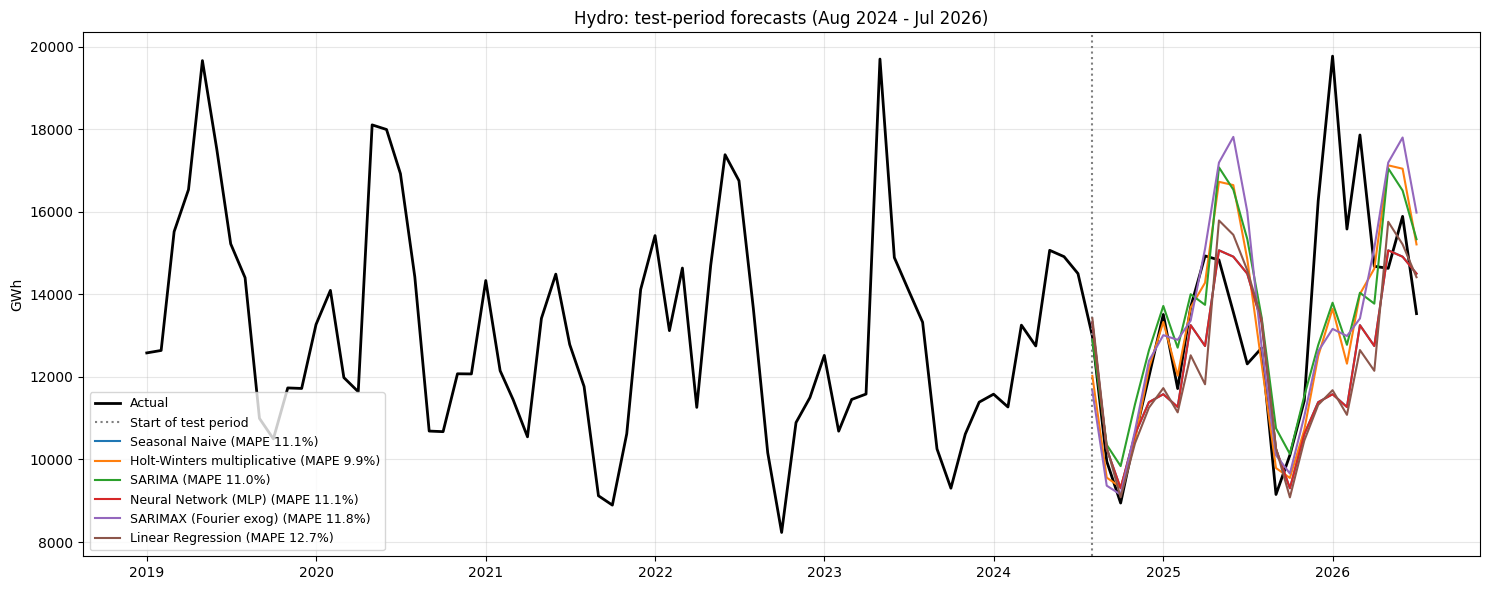

In [16]:
plot_forecasts("hydro", all_forecasts["hydro"], all_tables["hydro"])

In [17]:
#@title Interpretation (generated from the results above)
r = "hydro"
t = all_tables[r]
best, b, sn = t.index[0], t.iloc[0], t.loc["Seasonal Naive"]
n_beat = int((t["MASE"] < sn["MASE"]).sum())
improve = (1 - b["MAE"] / sn["MAE"]) * 100
top = t.head(3).reset_index()[["model", "family", "MAE", "RMSE", "MAPE", "MASE"]]
fam = t.groupby("family")[["MAPE", "MASE"]].min().sort_values("MASE")
fam_txt = "; ".join(f"{f} {row.MAPE:.1f}%" for f, row in fam.iterrows())
d_, D_ = diff_orders[r]
if best == "Seasonal Naive":
    sn_line = "The best model **is** the seasonal naive baseline, so no model improves on simply repeating last year's value for the same month."
else:
    sn_line = f"The best model's MAE is {abs(improve):.0f}% {'lower' if improve >= 0 else 'higher'} than the seasonal naive MAE."
mase_note = (" Note that a MASE above 1 does not by itself mean a poor model here: the MASE scale is the average seasonal-naive error on the training data, and for a fast-growing series that scale is small compared with the errors of the test years."
             if b["MASE"] > 1 else "")
close = (t["MASE"].iloc[1] - t["MASE"].iloc[0]) / t["MASE"].iloc[0] < 0.10
arima_vs = f"The non-seasonal ARIMA reaches a MAPE of {t.loc['ARIMA', 'MAPE']:.1f}%, against {t.loc['SARIMA', 'MAPE']:.1f}% for SARIMA."
grew = test[r].max() > train[r].max() * 1.05
NOTES = {
    "hydro": "Hydro depends on rainfall and snowpack, which are not in the data, so a sizeable error is expected whatever the model. The models can capture the typical yearly shape, not whether a particular year is wet or dry.",
    "solar": ("The test period contains values well above anything seen in training (the series keeps setting new highs), so every model has to extrapolate beyond the training range. "
              "That favours models that work on growth rates (log scale and differencing, or year-on-year changes) over models that repeat the past level.") if grew else
             "Solar growth continues, so models that work on growth rates (log scale and differencing) are expected to do best.",
    "biomass": "Biomass is a small, slowly changing series with a modest seasonal ripple and a recent decline. Accuracy depends mostly on how well a model carries the recent downward drift forward.",
    "geothermal": "Geothermal is nearly flat with a very small seasonal cycle, so most reasonable models land close together. Isolated unexplained dips (such as Nov 2019 in the data) cannot be forecast.",
}
show(f"""**Hydro: model results**

* **Best model on the test period: {best}**{'' if spec(r, best) == best else f' ({spec(r, best)})'}. MAE {b['MAE']:,.1f} GWh, RMSE {b['RMSE']:,.1f} GWh, **MAPE {b['MAPE']:.1f}%**, MASE {b['MASE']:.2f}.
* **Seasonal naive** (same month last year): MAPE {sn['MAPE']:.1f}%, MASE {sn['MASE']:.2f}. {sn_line}
* {n_beat} of the {len(t) - 1} other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: {fam_txt}.
* Differencing chosen on the training data: d = {d_}, D = {D_}. {arima_vs}

Top three models:

{md_table(top)}

{NOTES[r]}{mase_note}{' The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.' if close else ''}""")

**Hydro: model results**

* **Best model on the test period: Holt-Winters multiplicative**. MAE 1,474.5 GWh, RMSE 2,142.5 GWh, **MAPE 9.9%**, MASE 0.71.
* **Seasonal naive** (same month last year): MAPE 11.1%, MASE 0.81. The best model's MAE is 12% lower than the seasonal naive MAE.
* 2 of the 12 other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: Holt-Winters 9.9%; SARIMA 11.0%; Baseline 11.1%; Neural network 11.1%; SARIMAX 11.8%; ML 12.7%; ARIMA 17.4%; Exponential smoothing 19.5%.
* Differencing chosen on the training data: d = 0, D = 0. The non-seasonal ARIMA reaches a MAPE of 17.4%, against 11.0% for SARIMA.

Top three models:

| model | family | MAE | RMSE | MAPE | MASE |
|---|---|---|---|---|---|
| Holt-Winters multiplicative | Holt-Winters | 1474.52 | 2142.48 | 9.93 | 0.71 |
| SARIMA | SARIMA | 1585.38 | 2153.78 | 11.03 | 0.77 |
| Seasonal Naive | Baseline | 1668.62 | 2546.40 | 11.11 | 0.81 |

Hydro depends on rainfall and snowpack, which are not in the data, so a sizeable error is expected whatever the model. The models can capture the typical yearly shape, not whether a particular year is wet or dry. The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.

### 5.2 Residual analysis of the best hydro model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best hydro model on the test period: Holt-Winters multiplicative


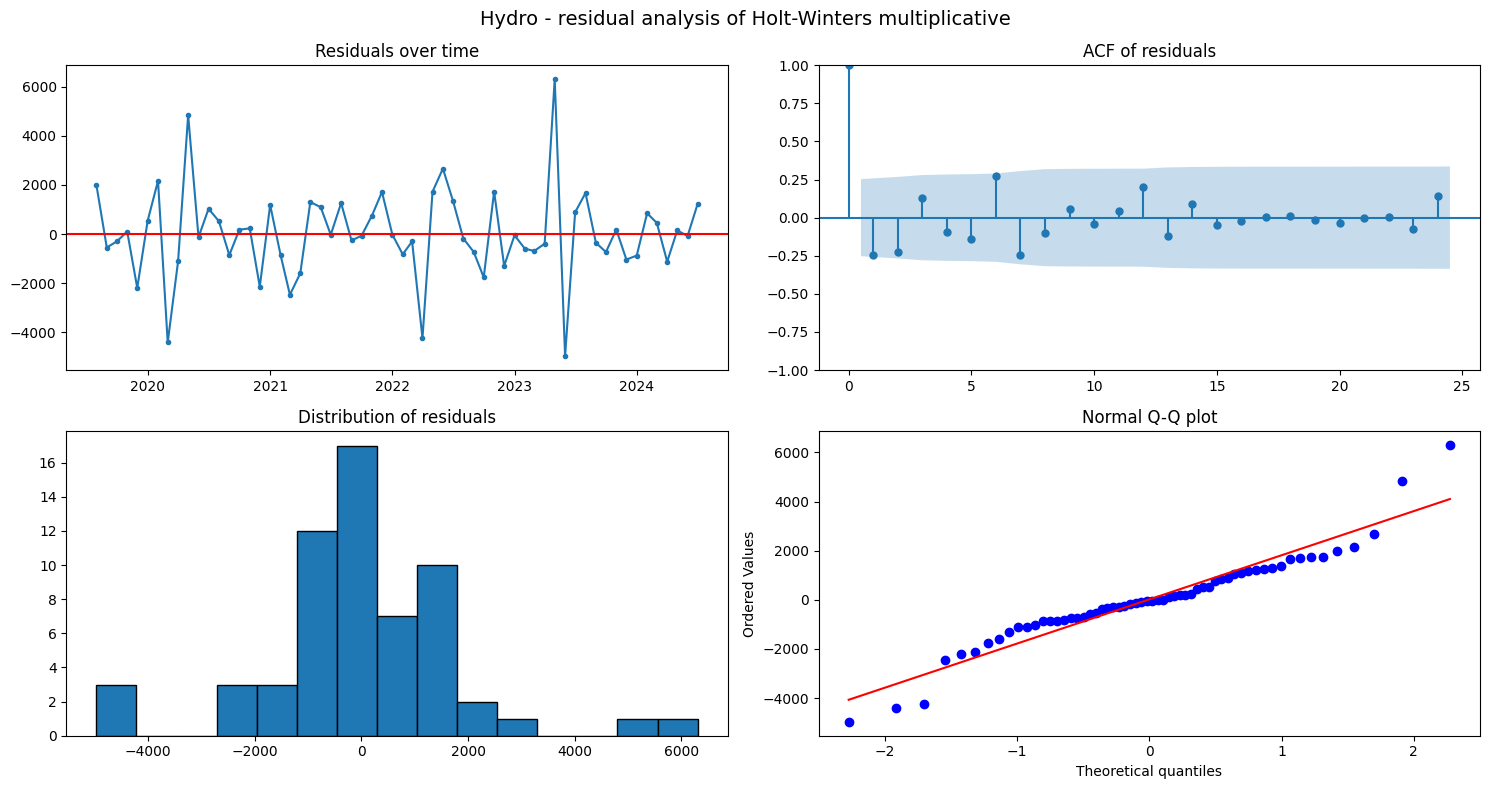

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,hydro,Holt-Winters multiplicative,60,15.582,0.948,1833.166,0.018,0.021,0.003


In [18]:
best_hydro = all_tables["hydro"].index[0]
print("Best hydro model on the test period:", best_hydro)
one_step_hydro, test_err_hydro = residual_analysis("hydro", best_hydro)
residual_rows.append(residual_report("hydro", best_hydro, one_step_hydro))
pd.DataFrame([residual_rows[-1]])

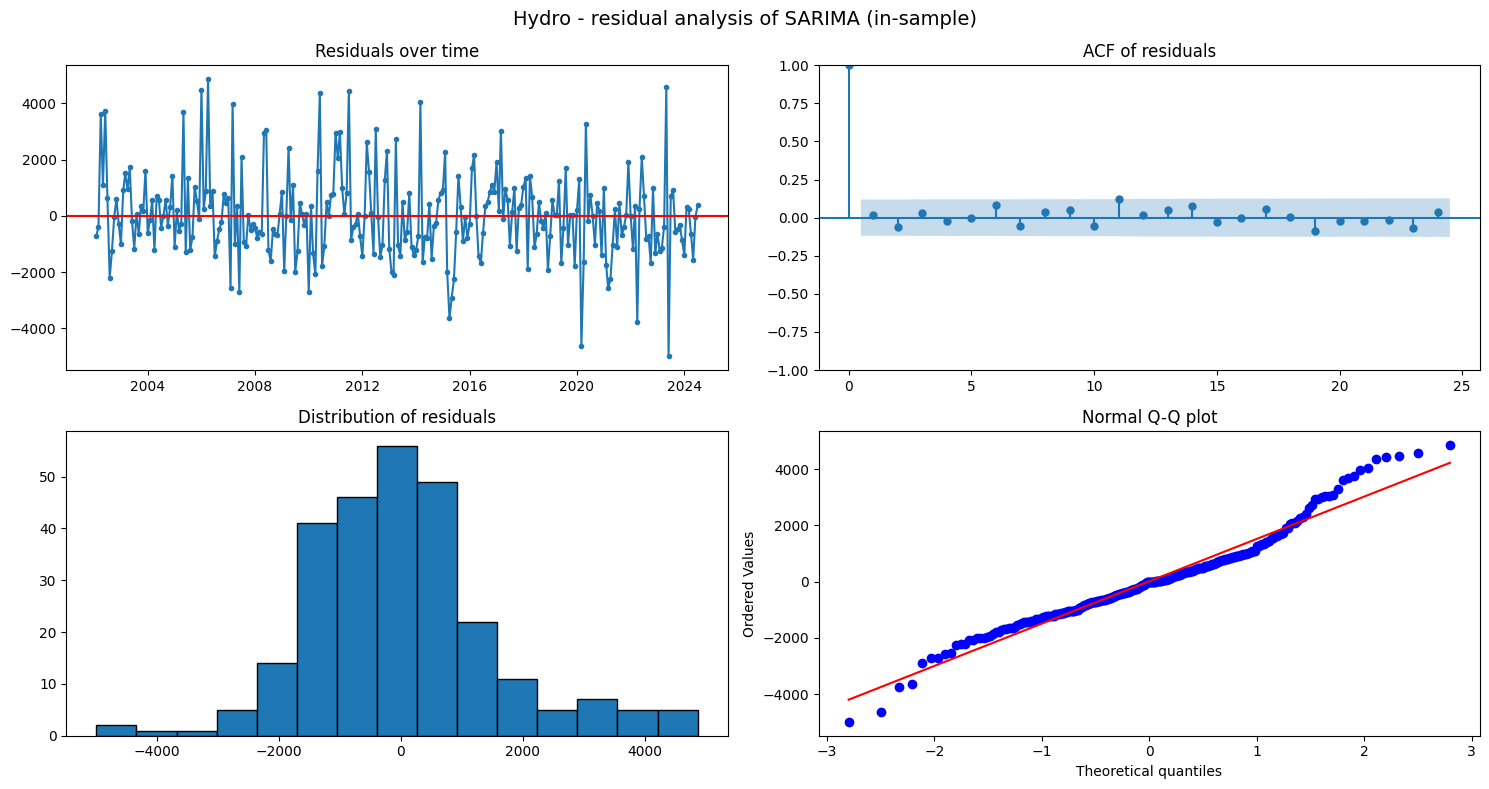

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.424e+04   2107.335      6.756      0.000    1.01e+04    1.84e+04
ar.L1          0.8567      0.052     16.615      0.000       0.756       0.958
ar.L2         -0.1223      0.051     -2.422      0.015      -0.221      -0.023
ar.S.L12       0.9861      0.012     85.464      0.000       0.963       1.009
ma.S.L12      -0.8217      0.055    -14.829      0.000      -0.930      -0.713
sigma2      2.211e+06   1.52e+05     14.550      0.000    1.91e+06    2.51e+06


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,hydro,SARIMA (in-sample),270,13.973,0.880,1523.909,0.767,0.541,0.000


In [19]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["hydro"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["hydro"], "hydro"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("hydro", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

In [20]:
#@title Interpretation (generated from the results above)
r = "hydro"
rb, rs = residual_rows[-2], residual_rows[-1]
def check(row):
    bias = row["mean t-test p"] < 0.05
    ac = min(row["Ljung-Box p (lag 6)"], row["Ljung-Box p (lag 12)"]) < 0.05
    nn = row["Shapiro-Wilk p"] < 0.05
    return bias, ac, nn
def describe(row, unit):
    bias, ac, nn = check(row)
    parts = [f"mean {row['mean']:+,.2f} {unit} (t-test p = {row['mean t-test p']:.3f}, {'**systematic bias**' if bias else 'no significant bias'})",
             f"Ljung-Box p = {row['Ljung-Box p (lag 6)']:.3f} (lag 6) and {row['Ljung-Box p (lag 12)']:.3f} (lag 12), {'**autocorrelation remains**' if ac else 'no significant autocorrelation'}",
             f"Shapiro-Wilk p = {row['Shapiro-Wilk p']:.3f}, {'residuals are **not normal**' if nn else 'residuals are consistent with a normal shape'}"]
    return "; ".join(parts) + "."
def overall(row):
    bias, ac, nn = check(row)
    if not (bias or ac): return "The residuals behave like **white noise**, so the model has captured the systematic structure."
    if ac and not bias: return "Some **structure is left in the residuals**, so the model leaves some predictable pattern unused."
    if bias and not ac: return "The residuals are uncorrelated but **biased**, so the model is systematically too high or too low."
    return "The residuals are both **biased and autocorrelated**, so the model is missing structure."
unit_s = "log units" if USE_LOG[r] else "GWh"
nn_note = ("Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable." if (check(rb)[2] or check(rs)[2])
           else "Residuals look normal, so normal-theory prediction intervals are reasonable.")
show(f"""**Hydro: residual interpretation**

* **{rb['model']}** (one-step-ahead errors, n = {rb['n']}, GWh): {describe(rb, 'GWh')} {overall(rb)}
* **SARIMA, in-sample** (fitted on the training data, n = {rs['n']}, {unit_s}): {describe(rs, 'log units' if USE_LOG[r] else 'GWh')} {overall(rs)}
* The one-step errors have standard deviation {rb['std']:,.1f} GWh (about {rb['std'] / series[r].iloc[-60:].mean() * 100:.1f}% of the typical monthly level). {nn_note}""")

**Hydro: residual interpretation**

* **Holt-Winters multiplicative** (one-step-ahead errors, n = 60, GWh): mean +15.58 GWh (t-test p = 0.948, no significant bias); Ljung-Box p = 0.018 (lag 6) and 0.021 (lag 12), **autocorrelation remains**; Shapiro-Wilk p = 0.003, residuals are **not normal**. Some **structure is left in the residuals**, so the model leaves some predictable pattern unused.
* **SARIMA, in-sample** (fitted on the training data, n = 270, GWh): mean +13.97 GWh (t-test p = 0.880, no significant bias); Ljung-Box p = 0.767 (lag 6) and 0.541 (lag 12), no significant autocorrelation; Shapiro-Wilk p = 0.000, residuals are **not normal**. The residuals behave like **white noise**, so the model has captured the systematic structure.
* The one-step errors have standard deviation 1,833.2 GWh (about 14.2% of the typical monthly level). Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable.

## 6. Solar — separate models

### 6.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [21]:
all_forecasts["solar"], all_tables["solar"] = run_all_models("solar")
all_tables["solar"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
SARIMA,SARIMA,606.063,848.275,6.392,1.865
Holt-Winters add. damped,Holt-Winters,622.065,764.210,7.491,1.914
Holt-Winters additive,Holt-Winters,625.259,771.143,7.365,1.924
Holt-Winters multiplicative,Holt-Winters,635.465,772.116,7.141,1.956
ARIMA,ARIMA,891.000,1136.813,10.184,2.742
Linear Regression,ML,1257.156,1634.965,13.855,3.869
Neural Network (MLP),Neural network,1462.751,1823.290,15.165,4.502
Random Forest,ML,1795.132,2302.810,19.173,5.524
Seasonal Naive,Baseline,2191.716,2349.845,24.261,6.745


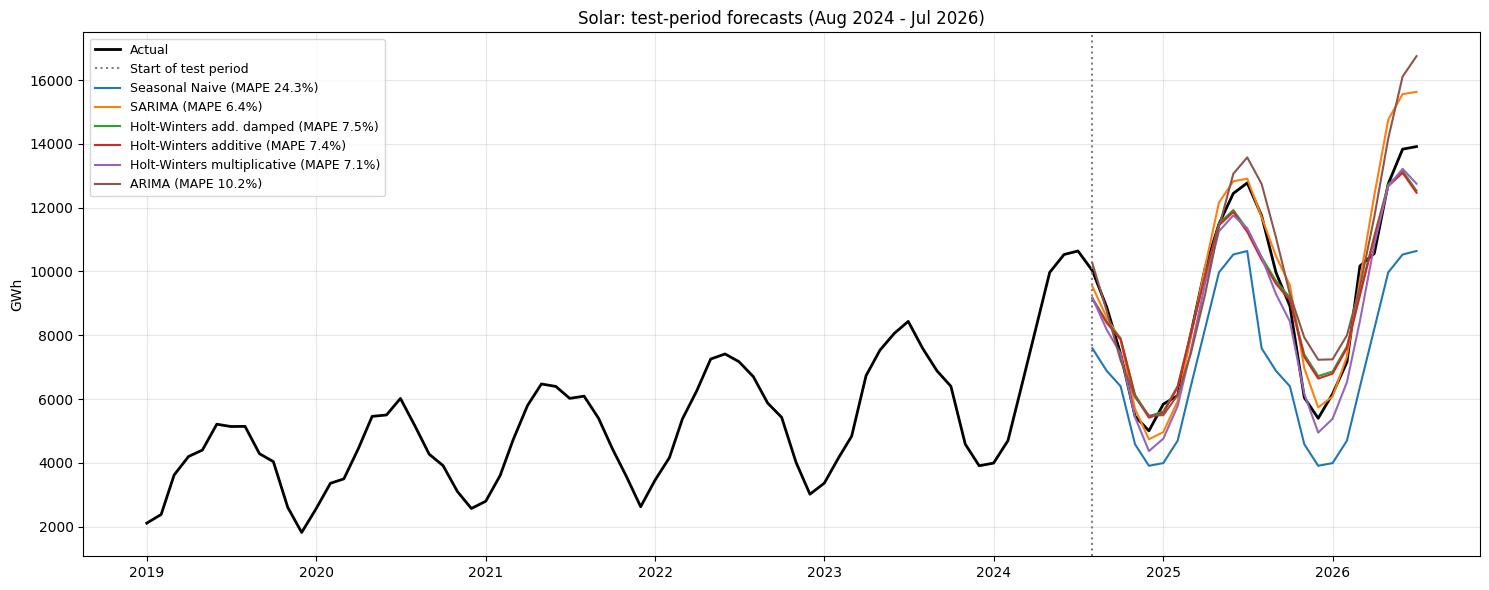

In [22]:
plot_forecasts("solar", all_forecasts["solar"], all_tables["solar"])

In [23]:
#@title Interpretation (generated from the results above)
r = "solar"
t = all_tables[r]
best, b, sn = t.index[0], t.iloc[0], t.loc["Seasonal Naive"]
n_beat = int((t["MASE"] < sn["MASE"]).sum())
improve = (1 - b["MAE"] / sn["MAE"]) * 100
top = t.head(3).reset_index()[["model", "family", "MAE", "RMSE", "MAPE", "MASE"]]
fam = t.groupby("family")[["MAPE", "MASE"]].min().sort_values("MASE")
fam_txt = "; ".join(f"{f} {row.MAPE:.1f}%" for f, row in fam.iterrows())
d_, D_ = diff_orders[r]
if best == "Seasonal Naive":
    sn_line = "The best model **is** the seasonal naive baseline, so no model improves on simply repeating last year's value for the same month."
else:
    sn_line = f"The best model's MAE is {abs(improve):.0f}% {'lower' if improve >= 0 else 'higher'} than the seasonal naive MAE."
mase_note = (" Note that a MASE above 1 does not by itself mean a poor model here: the MASE scale is the average seasonal-naive error on the training data, and for a fast-growing series that scale is small compared with the errors of the test years."
             if b["MASE"] > 1 else "")
close = (t["MASE"].iloc[1] - t["MASE"].iloc[0]) / t["MASE"].iloc[0] < 0.10
arima_vs = f"The non-seasonal ARIMA reaches a MAPE of {t.loc['ARIMA', 'MAPE']:.1f}%, against {t.loc['SARIMA', 'MAPE']:.1f}% for SARIMA."
grew = test[r].max() > train[r].max() * 1.05
NOTES = {
    "hydro": "Hydro depends on rainfall and snowpack, which are not in the data, so a sizeable error is expected whatever the model. The models can capture the typical yearly shape, not whether a particular year is wet or dry.",
    "solar": ("The test period contains values well above anything seen in training (the series keeps setting new highs), so every model has to extrapolate beyond the training range. "
              "That favours models that work on growth rates (log scale and differencing, or year-on-year changes) over models that repeat the past level.") if grew else
             "Solar growth continues, so models that work on growth rates (log scale and differencing) are expected to do best.",
    "biomass": "Biomass is a small, slowly changing series with a modest seasonal ripple and a recent decline. Accuracy depends mostly on how well a model carries the recent downward drift forward.",
    "geothermal": "Geothermal is nearly flat with a very small seasonal cycle, so most reasonable models land close together. Isolated unexplained dips (such as Nov 2019 in the data) cannot be forecast.",
}
show(f"""**Solar: model results**

* **Best model on the test period: {best}**{'' if spec(r, best) == best else f' ({spec(r, best)})'}. MAE {b['MAE']:,.1f} GWh, RMSE {b['RMSE']:,.1f} GWh, **MAPE {b['MAPE']:.1f}%**, MASE {b['MASE']:.2f}.
* **Seasonal naive** (same month last year): MAPE {sn['MAPE']:.1f}%, MASE {sn['MASE']:.2f}. {sn_line}
* {n_beat} of the {len(t) - 1} other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: {fam_txt}.
* Differencing chosen on the training data: d = {d_}, D = {D_}. {arima_vs}

Top three models:

{md_table(top)}

{NOTES[r]}{mase_note}{' The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.' if close else ''}""")

**Solar: model results**

* **Best model on the test period: SARIMA** (SARIMA(1,1,1)(1,1,1)12). MAE 606.1 GWh, RMSE 848.3 GWh, **MAPE 6.4%**, MASE 1.87.
* **Seasonal naive** (same month last year): MAPE 24.3%, MASE 6.74. The best model's MAE is 72% lower than the seasonal naive MAE.
* 8 of the 12 other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: SARIMA 6.4%; Holt-Winters 7.1%; ARIMA 10.2%; ML 13.9%; Neural network 15.2%; Baseline 24.3%; SARIMAX 24.1%; Exponential smoothing 37.9%.
* Differencing chosen on the training data: d = 1, D = 1. The non-seasonal ARIMA reaches a MAPE of 10.2%, against 6.4% for SARIMA.

Top three models:

| model | family | MAE | RMSE | MAPE | MASE |
|---|---|---|---|---|---|
| SARIMA | SARIMA | 606.06 | 848.27 | 6.39 | 1.87 |
| Holt-Winters add. damped | Holt-Winters | 622.06 | 764.21 | 7.49 | 1.91 |
| Holt-Winters additive | Holt-Winters | 625.26 | 771.14 | 7.36 | 1.92 |

The test period contains values well above anything seen in training (the series keeps setting new highs), so every model has to extrapolate beyond the training range. That favours models that work on growth rates (log scale and differencing, or year-on-year changes) over models that repeat the past level. Note that a MASE above 1 does not by itself mean a poor model here: the MASE scale is the average seasonal-naive error on the training data, and for a fast-growing series that scale is small compared with the errors of the test years. The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.

### 6.2 Residual analysis of the best solar model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best solar model on the test period: SARIMA


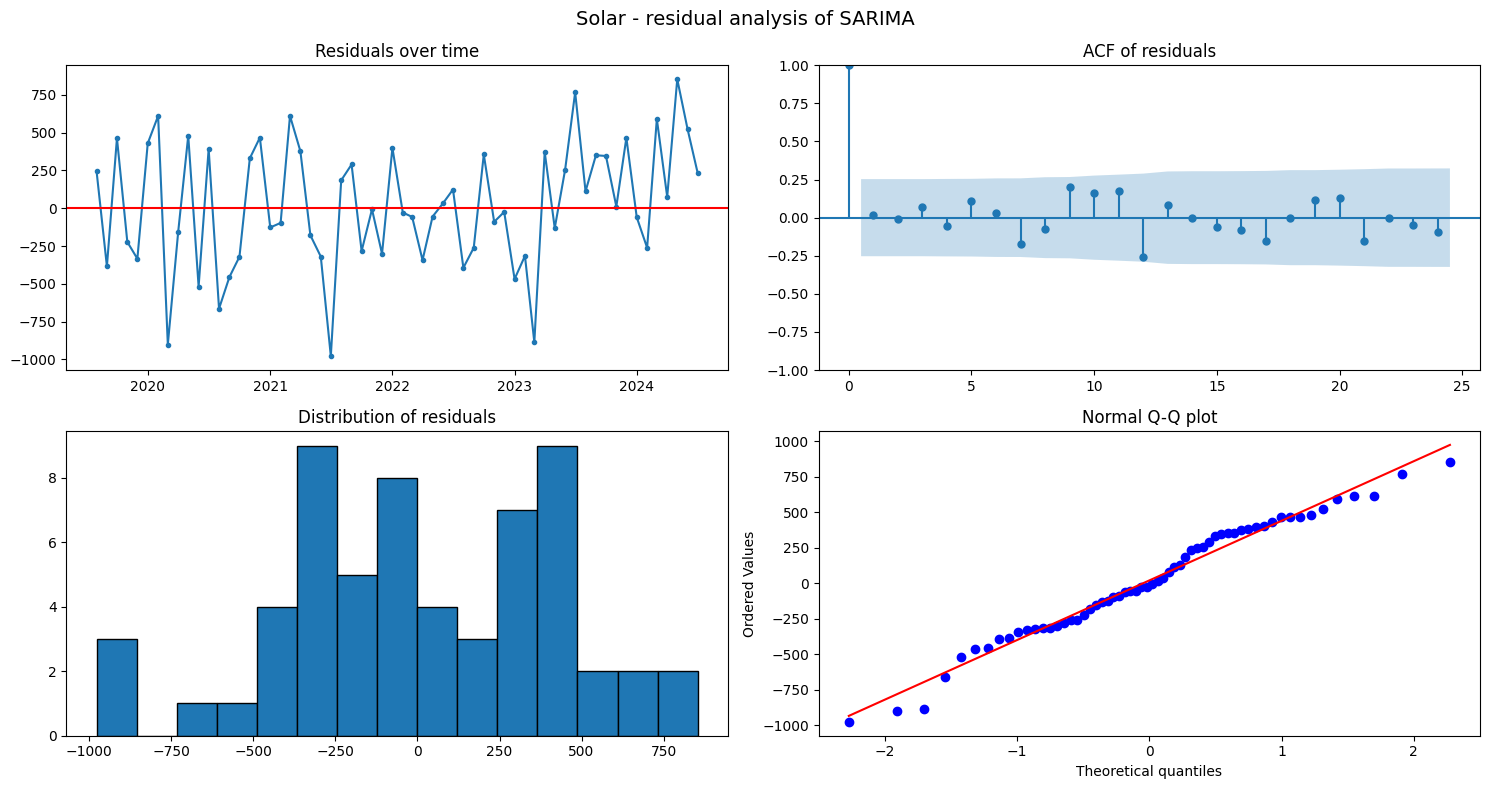

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,solar,SARIMA,60,18.949,0.724,414.457,0.968,0.182,0.334


In [24]:
best_solar = all_tables["solar"].index[0]
print("Best solar model on the test period:", best_solar)
one_step_solar, test_err_solar = residual_analysis("solar", best_solar)
residual_rows.append(residual_report("solar", best_solar, one_step_solar))
pd.DataFrame([residual_rows[-1]])

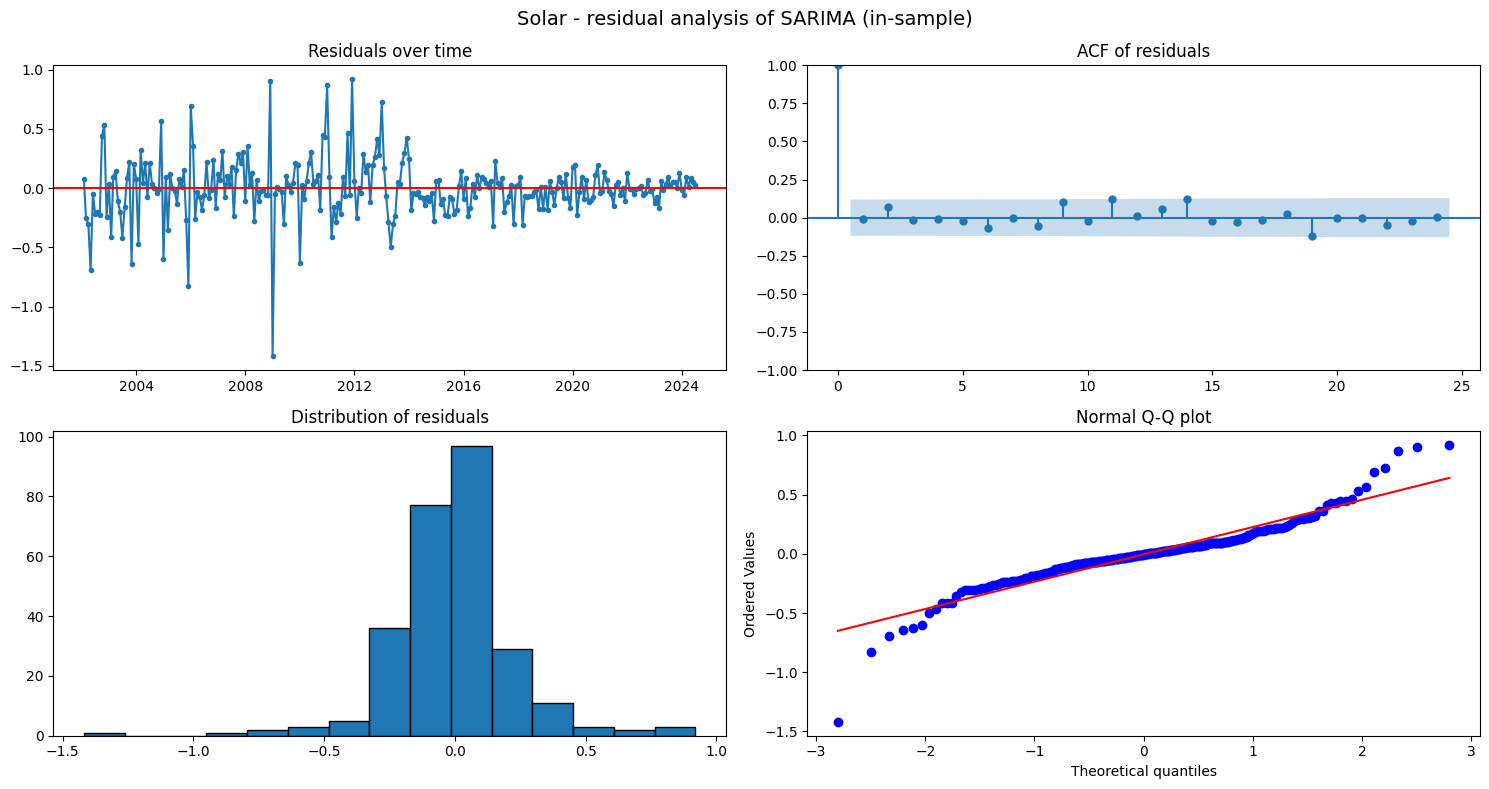

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1591      0.069      2.290      0.022       0.023       0.295
ma.L1         -0.7782      0.052    -15.102      0.000      -0.879      -0.677
ar.S.L12       0.4842      0.131      3.706      0.000       0.228       0.740
ma.S.L12      -0.7109      0.113     -6.282      0.000      -0.933      -0.489
sigma2         0.0576      0.003     20.122      0.000       0.052       0.063


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,solar,SARIMA (in-sample),270,-0.004,0.761,0.242,0.814,0.507,0.000


In [25]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["solar"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["solar"], "solar"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("solar", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

In [26]:
#@title Interpretation (generated from the results above)
r = "solar"
rb, rs = residual_rows[-2], residual_rows[-1]
def check(row):
    bias = row["mean t-test p"] < 0.05
    ac = min(row["Ljung-Box p (lag 6)"], row["Ljung-Box p (lag 12)"]) < 0.05
    nn = row["Shapiro-Wilk p"] < 0.05
    return bias, ac, nn
def describe(row, unit):
    bias, ac, nn = check(row)
    parts = [f"mean {row['mean']:+,.2f} {unit} (t-test p = {row['mean t-test p']:.3f}, {'**systematic bias**' if bias else 'no significant bias'})",
             f"Ljung-Box p = {row['Ljung-Box p (lag 6)']:.3f} (lag 6) and {row['Ljung-Box p (lag 12)']:.3f} (lag 12), {'**autocorrelation remains**' if ac else 'no significant autocorrelation'}",
             f"Shapiro-Wilk p = {row['Shapiro-Wilk p']:.3f}, {'residuals are **not normal**' if nn else 'residuals are consistent with a normal shape'}"]
    return "; ".join(parts) + "."
def overall(row):
    bias, ac, nn = check(row)
    if not (bias or ac): return "The residuals behave like **white noise**, so the model has captured the systematic structure."
    if ac and not bias: return "Some **structure is left in the residuals**, so the model leaves some predictable pattern unused."
    if bias and not ac: return "The residuals are uncorrelated but **biased**, so the model is systematically too high or too low."
    return "The residuals are both **biased and autocorrelated**, so the model is missing structure."
unit_s = "log units" if USE_LOG[r] else "GWh"
nn_note = ("Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable." if (check(rb)[2] or check(rs)[2])
           else "Residuals look normal, so normal-theory prediction intervals are reasonable.")
show(f"""**Solar: residual interpretation**

* **{rb['model']}** (one-step-ahead errors, n = {rb['n']}, GWh): {describe(rb, 'GWh')} {overall(rb)}
* **SARIMA, in-sample** (fitted on the training data, n = {rs['n']}, {unit_s}): {describe(rs, 'log units' if USE_LOG[r] else 'GWh')} {overall(rs)}
* The one-step errors have standard deviation {rb['std']:,.1f} GWh (about {rb['std'] / series[r].iloc[-60:].mean() * 100:.1f}% of the typical monthly level). {nn_note}""")

**Solar: residual interpretation**

* **SARIMA** (one-step-ahead errors, n = 60, GWh): mean +18.95 GWh (t-test p = 0.724, no significant bias); Ljung-Box p = 0.968 (lag 6) and 0.182 (lag 12), no significant autocorrelation; Shapiro-Wilk p = 0.334, residuals are consistent with a normal shape. The residuals behave like **white noise**, so the model has captured the systematic structure.
* **SARIMA, in-sample** (fitted on the training data, n = 270, log units): mean -0.00 log units (t-test p = 0.761, no significant bias); Ljung-Box p = 0.814 (lag 6) and 0.507 (lag 12), no significant autocorrelation; Shapiro-Wilk p = 0.000, residuals are **not normal**. The residuals behave like **white noise**, so the model has captured the systematic structure.
* The one-step errors have standard deviation 414.5 GWh (about 5.7% of the typical monthly level). Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable.

## 7. Biomass — separate models

### 7.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [27]:
all_forecasts["biomass"], all_tables["biomass"] = run_all_models("biomass")
all_tables["biomass"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
SARIMA,SARIMA,32.179,40.320,5.178,0.726
Holt-Winters multiplicative,Holt-Winters,32.743,38.598,5.305,0.738
Neural Network (MLP),Neural network,45.494,57.152,7.310,1.026
Holt-Winters add. damped,Holt-Winters,49.985,60.253,8.114,1.127
Holt-Winters additive,Holt-Winters,51.599,62.043,8.381,1.164
Linear Regression,ML,52.022,64.752,8.386,1.173
SES,Exponential smoothing,53.080,62.075,8.759,1.197
Holt (damped),Exponential smoothing,53.258,62.315,8.789,1.201
SARIMAX (Fourier exog),SARIMAX,53.700,62.816,8.757,1.211


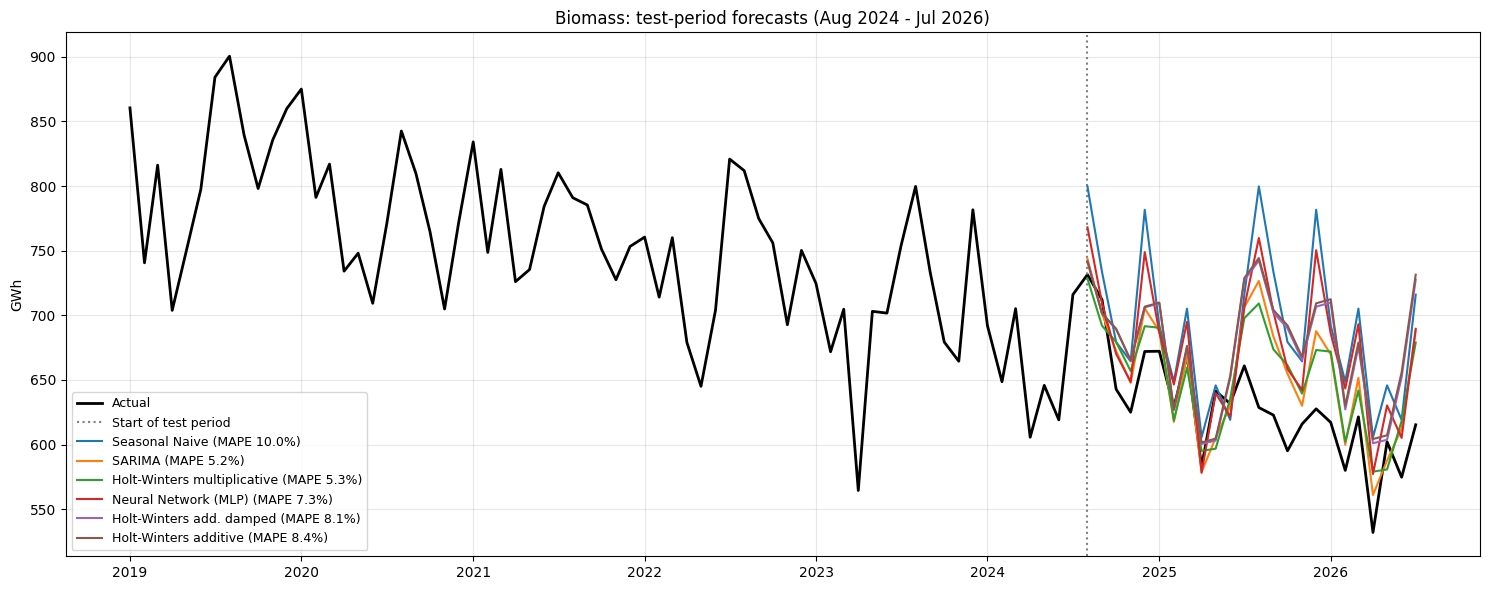

In [28]:
plot_forecasts("biomass", all_forecasts["biomass"], all_tables["biomass"])

In [29]:
#@title Interpretation (generated from the results above)
r = "biomass"
t = all_tables[r]
best, b, sn = t.index[0], t.iloc[0], t.loc["Seasonal Naive"]
n_beat = int((t["MASE"] < sn["MASE"]).sum())
improve = (1 - b["MAE"] / sn["MAE"]) * 100
top = t.head(3).reset_index()[["model", "family", "MAE", "RMSE", "MAPE", "MASE"]]
fam = t.groupby("family")[["MAPE", "MASE"]].min().sort_values("MASE")
fam_txt = "; ".join(f"{f} {row.MAPE:.1f}%" for f, row in fam.iterrows())
d_, D_ = diff_orders[r]
if best == "Seasonal Naive":
    sn_line = "The best model **is** the seasonal naive baseline, so no model improves on simply repeating last year's value for the same month."
else:
    sn_line = f"The best model's MAE is {abs(improve):.0f}% {'lower' if improve >= 0 else 'higher'} than the seasonal naive MAE."
mase_note = (" Note that a MASE above 1 does not by itself mean a poor model here: the MASE scale is the average seasonal-naive error on the training data, and for a fast-growing series that scale is small compared with the errors of the test years."
             if b["MASE"] > 1 else "")
close = (t["MASE"].iloc[1] - t["MASE"].iloc[0]) / t["MASE"].iloc[0] < 0.10
arima_vs = f"The non-seasonal ARIMA reaches a MAPE of {t.loc['ARIMA', 'MAPE']:.1f}%, against {t.loc['SARIMA', 'MAPE']:.1f}% for SARIMA."
grew = test[r].max() > train[r].max() * 1.05
NOTES = {
    "hydro": "Hydro depends on rainfall and snowpack, which are not in the data, so a sizeable error is expected whatever the model. The models can capture the typical yearly shape, not whether a particular year is wet or dry.",
    "solar": ("The test period contains values well above anything seen in training (the series keeps setting new highs), so every model has to extrapolate beyond the training range. "
              "That favours models that work on growth rates (log scale and differencing, or year-on-year changes) over models that repeat the past level.") if grew else
             "Solar growth continues, so models that work on growth rates (log scale and differencing) are expected to do best.",
    "biomass": "Biomass is a small, slowly changing series with a modest seasonal ripple and a recent decline. Accuracy depends mostly on how well a model carries the recent downward drift forward.",
    "geothermal": "Geothermal is nearly flat with a very small seasonal cycle, so most reasonable models land close together. Isolated unexplained dips (such as Nov 2019 in the data) cannot be forecast.",
}
show(f"""**Biomass: model results**

* **Best model on the test period: {best}**{'' if spec(r, best) == best else f' ({spec(r, best)})'}. MAE {b['MAE']:,.1f} GWh, RMSE {b['RMSE']:,.1f} GWh, **MAPE {b['MAPE']:.1f}%**, MASE {b['MASE']:.2f}.
* **Seasonal naive** (same month last year): MAPE {sn['MAPE']:.1f}%, MASE {sn['MASE']:.2f}. {sn_line}
* {n_beat} of the {len(t) - 1} other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: {fam_txt}.
* Differencing chosen on the training data: d = {d_}, D = {D_}. {arima_vs}

Top three models:

{md_table(top)}

{NOTES[r]}{mase_note}{' The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.' if close else ''}""")

**Biomass: model results**

* **Best model on the test period: SARIMA** (SARIMA(0,1,2)(0,1,1)12). MAE 32.2 GWh, RMSE 40.3 GWh, **MAPE 5.2%**, MASE 0.73.
* **Seasonal naive** (same month last year): MAPE 10.0%, MASE 1.41. The best model's MAE is 49% lower than the seasonal naive MAE.
* 10 of the 12 other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: SARIMA 5.2%; Holt-Winters 5.3%; Neural network 7.3%; ML 8.4%; Exponential smoothing 8.8%; SARIMAX 8.8%; Baseline 10.0%; ARIMA 11.4%.
* Differencing chosen on the training data: d = 1, D = 1. The non-seasonal ARIMA reaches a MAPE of 11.4%, against 5.2% for SARIMA.

Top three models:

| model | family | MAE | RMSE | MAPE | MASE |
|---|---|---|---|---|---|
| SARIMA | SARIMA | 32.18 | 40.32 | 5.18 | 0.73 |
| Holt-Winters multiplicative | Holt-Winters | 32.74 | 38.60 | 5.31 | 0.74 |
| Neural Network (MLP) | Neural network | 45.49 | 57.15 | 7.31 | 1.03 |

Biomass is a small, slowly changing series with a modest seasonal ripple and a recent decline. Accuracy depends mostly on how well a model carries the recent downward drift forward. The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.

### 7.2 Residual analysis of the best biomass model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best biomass model on the test period: SARIMA


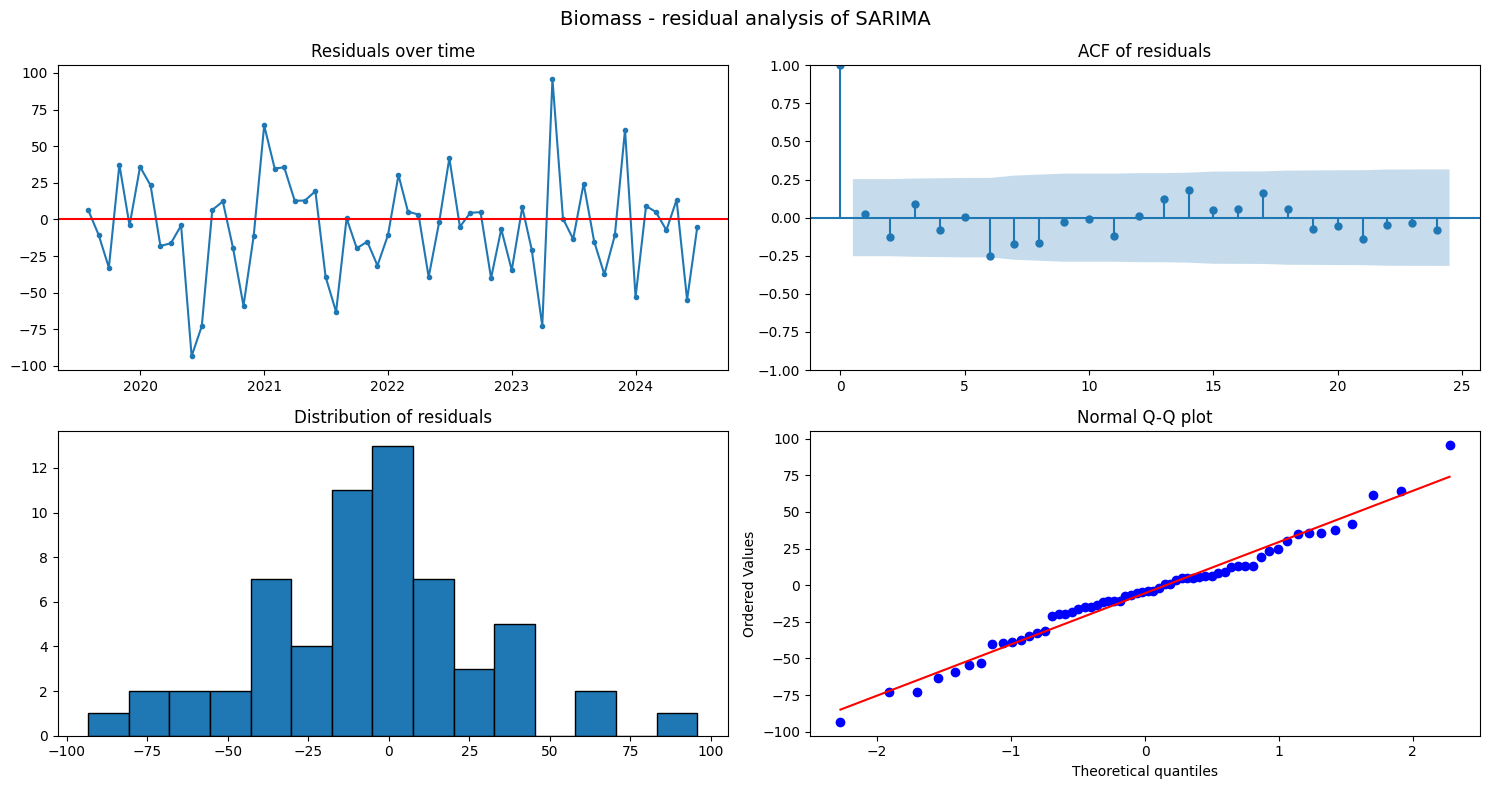

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,biomass,SARIMA,60,-5.479,0.225,34.600,0.375,0.473,0.494


In [30]:
best_biomass = all_tables["biomass"].index[0]
print("Best biomass model on the test period:", best_biomass)
one_step_biomass, test_err_biomass = residual_analysis("biomass", best_biomass)
residual_rows.append(residual_report("biomass", best_biomass, one_step_biomass))
pd.DataFrame([residual_rows[-1]])

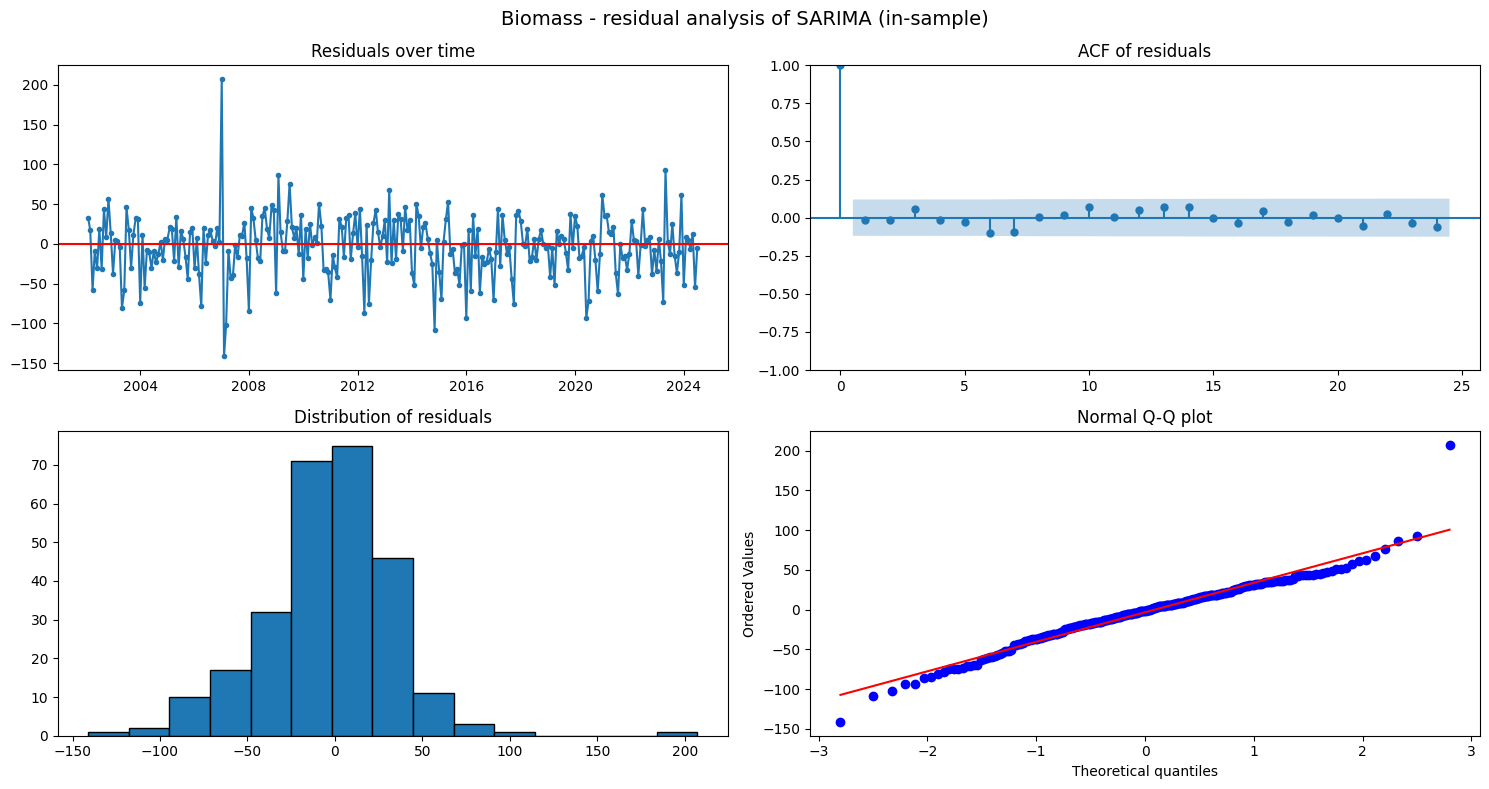

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5716      0.039    -14.762      0.000      -0.647      -0.496
ma.L2         -0.1069      0.043     -2.509      0.012      -0.190      -0.023
ma.S.L12      -0.8365      0.047    -17.737      0.000      -0.929      -0.744
sigma2      1365.6047     77.003     17.734      0.000    1214.682    1516.528


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,biomass,SARIMA (in-sample),270,-3.283,0.154,37.755,0.699,0.743,0.000


In [31]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["biomass"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["biomass"], "biomass"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("biomass", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

In [32]:
#@title Interpretation (generated from the results above)
r = "biomass"
rb, rs = residual_rows[-2], residual_rows[-1]
def check(row):
    bias = row["mean t-test p"] < 0.05
    ac = min(row["Ljung-Box p (lag 6)"], row["Ljung-Box p (lag 12)"]) < 0.05
    nn = row["Shapiro-Wilk p"] < 0.05
    return bias, ac, nn
def describe(row, unit):
    bias, ac, nn = check(row)
    parts = [f"mean {row['mean']:+,.2f} {unit} (t-test p = {row['mean t-test p']:.3f}, {'**systematic bias**' if bias else 'no significant bias'})",
             f"Ljung-Box p = {row['Ljung-Box p (lag 6)']:.3f} (lag 6) and {row['Ljung-Box p (lag 12)']:.3f} (lag 12), {'**autocorrelation remains**' if ac else 'no significant autocorrelation'}",
             f"Shapiro-Wilk p = {row['Shapiro-Wilk p']:.3f}, {'residuals are **not normal**' if nn else 'residuals are consistent with a normal shape'}"]
    return "; ".join(parts) + "."
def overall(row):
    bias, ac, nn = check(row)
    if not (bias or ac): return "The residuals behave like **white noise**, so the model has captured the systematic structure."
    if ac and not bias: return "Some **structure is left in the residuals**, so the model leaves some predictable pattern unused."
    if bias and not ac: return "The residuals are uncorrelated but **biased**, so the model is systematically too high or too low."
    return "The residuals are both **biased and autocorrelated**, so the model is missing structure."
unit_s = "log units" if USE_LOG[r] else "GWh"
nn_note = ("Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable." if (check(rb)[2] or check(rs)[2])
           else "Residuals look normal, so normal-theory prediction intervals are reasonable.")
show(f"""**Biomass: residual interpretation**

* **{rb['model']}** (one-step-ahead errors, n = {rb['n']}, GWh): {describe(rb, 'GWh')} {overall(rb)}
* **SARIMA, in-sample** (fitted on the training data, n = {rs['n']}, {unit_s}): {describe(rs, 'log units' if USE_LOG[r] else 'GWh')} {overall(rs)}
* The one-step errors have standard deviation {rb['std']:,.1f} GWh (about {rb['std'] / series[r].iloc[-60:].mean() * 100:.1f}% of the typical monthly level). {nn_note}""")

**Biomass: residual interpretation**

* **SARIMA** (one-step-ahead errors, n = 60, GWh): mean -5.48 GWh (t-test p = 0.225, no significant bias); Ljung-Box p = 0.375 (lag 6) and 0.473 (lag 12), no significant autocorrelation; Shapiro-Wilk p = 0.494, residuals are consistent with a normal shape. The residuals behave like **white noise**, so the model has captured the systematic structure.
* **SARIMA, in-sample** (fitted on the training data, n = 270, GWh): mean -3.28 GWh (t-test p = 0.154, no significant bias); Ljung-Box p = 0.699 (lag 6) and 0.743 (lag 12), no significant autocorrelation; Shapiro-Wilk p = 0.000, residuals are **not normal**. The residuals behave like **white noise**, so the model has captured the systematic structure.
* The one-step errors have standard deviation 34.6 GWh (about 5.1% of the typical monthly level). Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable.

## 8. Geothermal — separate models

### 8.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [33]:
all_forecasts["geothermal"], all_tables["geothermal"] = run_all_models("geothermal")
all_tables["geothermal"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
SES,Exponential smoothing,53.786,60.830,4.174,1.099
SARIMA,SARIMA,56.837,65.545,4.461,1.162
Holt (damped),Exponential smoothing,63.823,71.670,5.004,1.304
Neural Network (MLP),Neural network,67.739,82.269,5.266,1.384
Seasonal Naive,Baseline,68.898,83.826,5.358,1.408
Random Forest,ML,71.034,88.665,5.547,1.452
Linear Regression,ML,71.656,86.788,5.581,1.464
SARIMAX (Fourier exog),SARIMAX,72.455,82.871,5.705,1.481
ARIMA,ARIMA,75.724,85.967,5.956,1.548


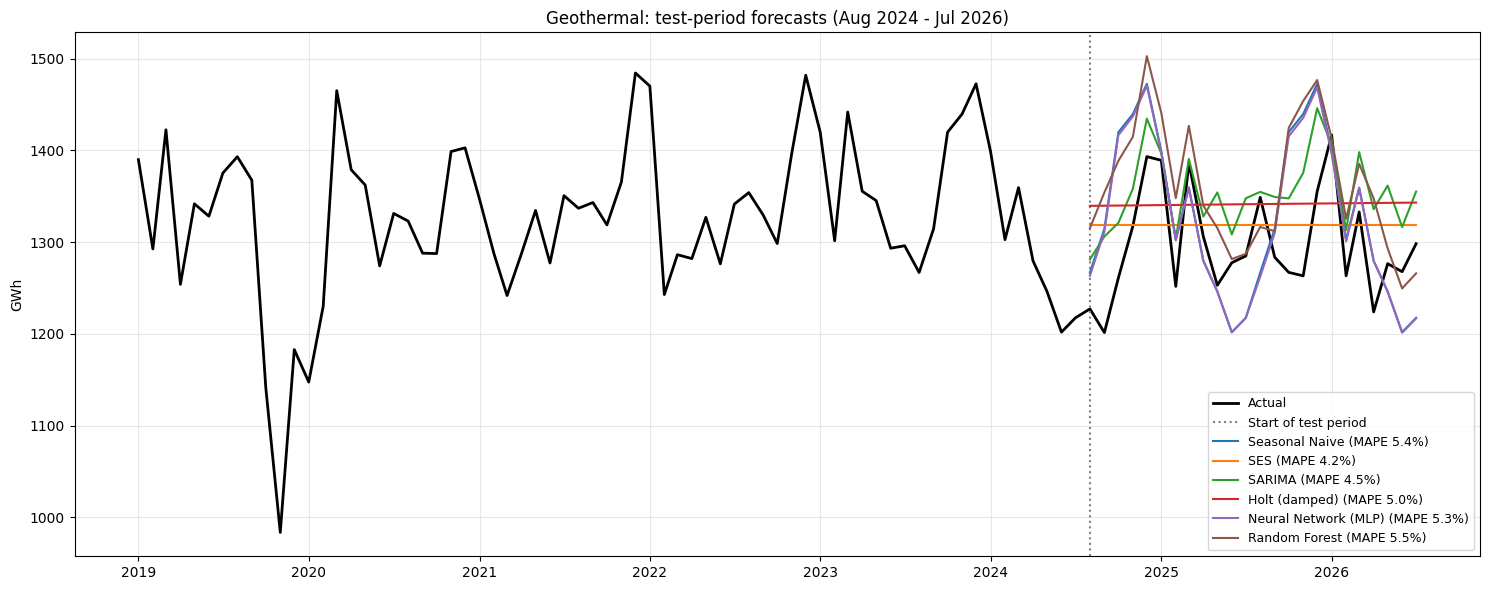

In [34]:
plot_forecasts("geothermal", all_forecasts["geothermal"], all_tables["geothermal"])

In [35]:
#@title Interpretation (generated from the results above)
r = "geothermal"
t = all_tables[r]
best, b, sn = t.index[0], t.iloc[0], t.loc["Seasonal Naive"]
n_beat = int((t["MASE"] < sn["MASE"]).sum())
improve = (1 - b["MAE"] / sn["MAE"]) * 100
top = t.head(3).reset_index()[["model", "family", "MAE", "RMSE", "MAPE", "MASE"]]
fam = t.groupby("family")[["MAPE", "MASE"]].min().sort_values("MASE")
fam_txt = "; ".join(f"{f} {row.MAPE:.1f}%" for f, row in fam.iterrows())
d_, D_ = diff_orders[r]
if best == "Seasonal Naive":
    sn_line = "The best model **is** the seasonal naive baseline, so no model improves on simply repeating last year's value for the same month."
else:
    sn_line = f"The best model's MAE is {abs(improve):.0f}% {'lower' if improve >= 0 else 'higher'} than the seasonal naive MAE."
mase_note = (" Note that a MASE above 1 does not by itself mean a poor model here: the MASE scale is the average seasonal-naive error on the training data, and for a fast-growing series that scale is small compared with the errors of the test years."
             if b["MASE"] > 1 else "")
close = (t["MASE"].iloc[1] - t["MASE"].iloc[0]) / t["MASE"].iloc[0] < 0.10
arima_vs = f"The non-seasonal ARIMA reaches a MAPE of {t.loc['ARIMA', 'MAPE']:.1f}%, against {t.loc['SARIMA', 'MAPE']:.1f}% for SARIMA."
grew = test[r].max() > train[r].max() * 1.05
NOTES = {
    "hydro": "Hydro depends on rainfall and snowpack, which are not in the data, so a sizeable error is expected whatever the model. The models can capture the typical yearly shape, not whether a particular year is wet or dry.",
    "solar": ("The test period contains values well above anything seen in training (the series keeps setting new highs), so every model has to extrapolate beyond the training range. "
              "That favours models that work on growth rates (log scale and differencing, or year-on-year changes) over models that repeat the past level.") if grew else
             "Solar growth continues, so models that work on growth rates (log scale and differencing) are expected to do best.",
    "biomass": "Biomass is a small, slowly changing series with a modest seasonal ripple and a recent decline. Accuracy depends mostly on how well a model carries the recent downward drift forward.",
    "geothermal": "Geothermal is nearly flat with a very small seasonal cycle, so most reasonable models land close together. Isolated unexplained dips (such as Nov 2019 in the data) cannot be forecast.",
}
show(f"""**Geothermal: model results**

* **Best model on the test period: {best}**{'' if spec(r, best) == best else f' ({spec(r, best)})'}. MAE {b['MAE']:,.1f} GWh, RMSE {b['RMSE']:,.1f} GWh, **MAPE {b['MAPE']:.1f}%**, MASE {b['MASE']:.2f}.
* **Seasonal naive** (same month last year): MAPE {sn['MAPE']:.1f}%, MASE {sn['MASE']:.2f}. {sn_line}
* {n_beat} of the {len(t) - 1} other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: {fam_txt}.
* Differencing chosen on the training data: d = {d_}, D = {D_}. {arima_vs}

Top three models:

{md_table(top)}

{NOTES[r]}{mase_note}{' The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.' if close else ''}""")

**Geothermal: model results**

* **Best model on the test period: SES**. MAE 53.8 GWh, RMSE 60.8 GWh, **MAPE 4.2%**, MASE 1.10.
* **Seasonal naive** (same month last year): MAPE 5.4%, MASE 1.41. The best model's MAE is 22% lower than the seasonal naive MAE.
* 4 of the 12 other models have a lower MASE than seasonal naive. MASE below 1 means a better error than seasonal naive achieves on the training data.
* Best MAPE by model family: Exponential smoothing 4.2%; SARIMA 4.5%; Neural network 5.3%; Baseline 5.4%; ML 5.5%; SARIMAX 5.7%; ARIMA 6.0%; Holt-Winters 6.2%.
* Differencing chosen on the training data: d = 1, D = 0. The non-seasonal ARIMA reaches a MAPE of 6.0%, against 4.5% for SARIMA.

Top three models:

| model | family | MAE | RMSE | MAPE | MASE |
|---|---|---|---|---|---|
| SES | Exponential smoothing | 53.79 | 60.83 | 4.17 | 1.10 |
| SARIMA | SARIMA | 56.84 | 65.55 | 4.46 | 1.16 |
| Holt (damped) | Exponential smoothing | 63.82 | 71.67 | 5.00 | 1.30 |

Geothermal is nearly flat with a very small seasonal cycle, so most reasonable models land close together. Isolated unexplained dips (such as Nov 2019 in the data) cannot be forecast. Note that a MASE above 1 does not by itself mean a poor model here: the MASE scale is the average seasonal-naive error on the training data, and for a fast-growing series that scale is small compared with the errors of the test years. The top models are within 10% of each other on MASE, and with only 24 test months such small differences are **not statistically meaningful**.

### 8.2 Residual analysis of the best geothermal model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best geothermal model on the test period: SES


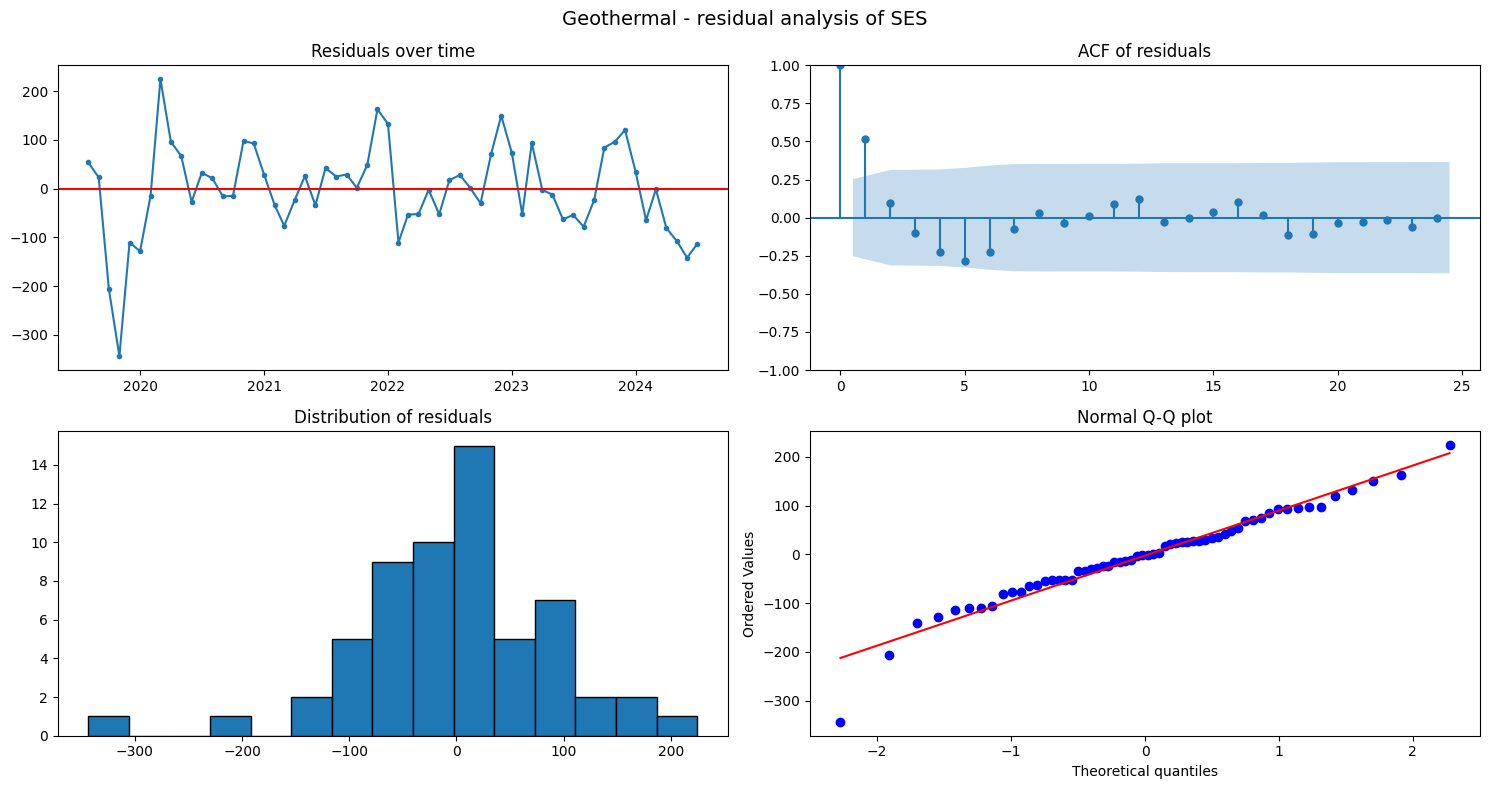

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,geothermal,SES,60,-2.396,0.842,92.527,0.000,0.001,0.081


In [36]:
best_geothermal = all_tables["geothermal"].index[0]
print("Best geothermal model on the test period:", best_geothermal)
one_step_geothermal, test_err_geothermal = residual_analysis("geothermal", best_geothermal)
residual_rows.append(residual_report("geothermal", best_geothermal, one_step_geothermal))
pd.DataFrame([residual_rows[-1]])

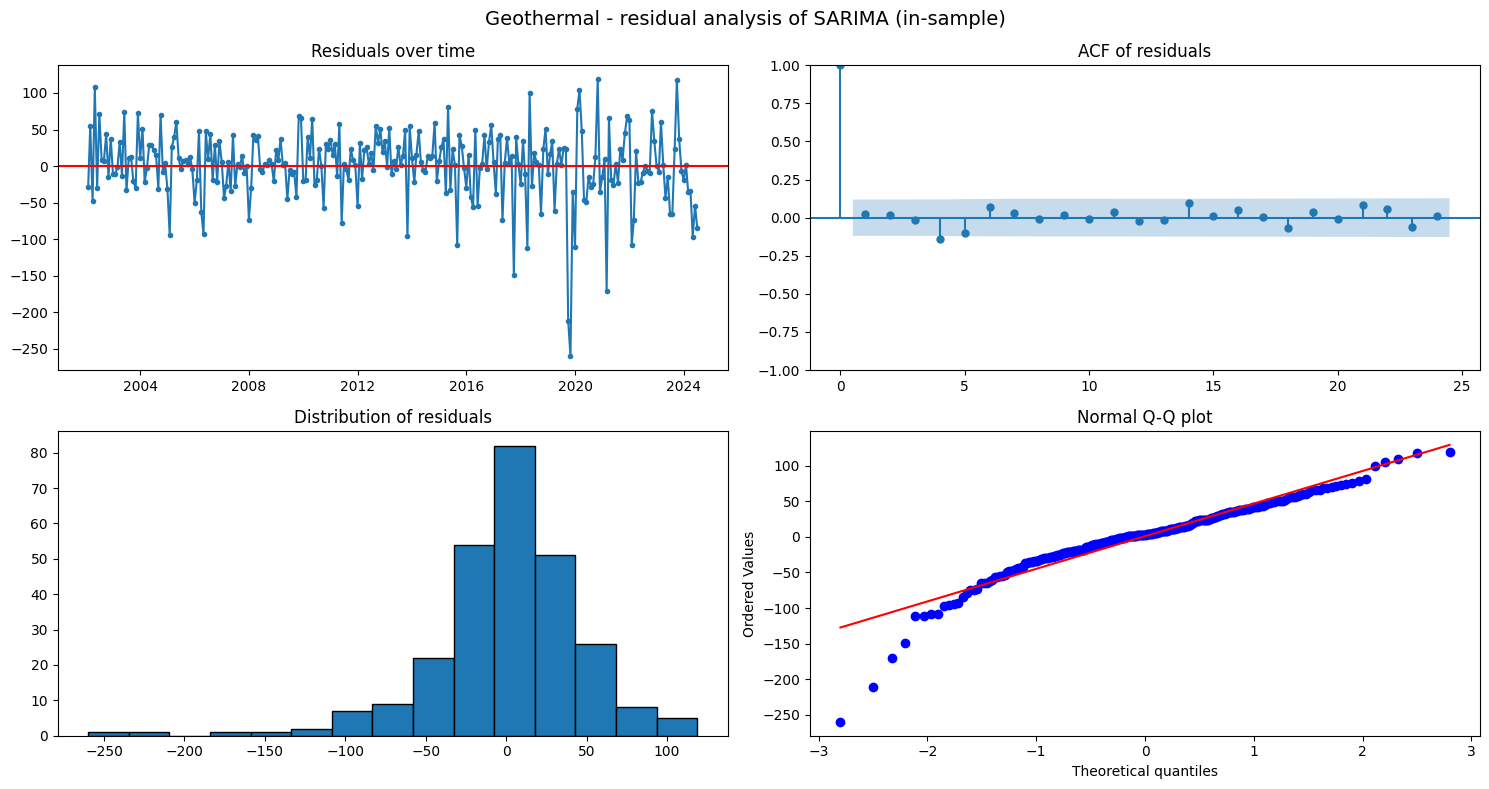

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.6002      0.292      2.058      0.040       0.028       1.172
ar.L1          0.5398      0.038     14.336      0.000       0.466       0.614
ma.L1         -0.9965      0.010   -100.316      0.000      -1.016      -0.977
ar.S.L12       0.9841      0.010    103.495      0.000       0.965       1.003
ma.S.L12      -0.8126      0.039    -20.753      0.000      -0.889      -0.736
sigma2      2189.1157    135.179     16.194      0.000    1924.171    2454.061


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,geothermal,SARIMA (in-sample),270,0.826,0.775,47.379,0.127,0.536,0.000


In [37]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["geothermal"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["geothermal"], "geothermal"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("geothermal", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

In [38]:
#@title Interpretation (generated from the results above)
r = "geothermal"
rb, rs = residual_rows[-2], residual_rows[-1]
def check(row):
    bias = row["mean t-test p"] < 0.05
    ac = min(row["Ljung-Box p (lag 6)"], row["Ljung-Box p (lag 12)"]) < 0.05
    nn = row["Shapiro-Wilk p"] < 0.05
    return bias, ac, nn
def describe(row, unit):
    bias, ac, nn = check(row)
    parts = [f"mean {row['mean']:+,.2f} {unit} (t-test p = {row['mean t-test p']:.3f}, {'**systematic bias**' if bias else 'no significant bias'})",
             f"Ljung-Box p = {row['Ljung-Box p (lag 6)']:.3f} (lag 6) and {row['Ljung-Box p (lag 12)']:.3f} (lag 12), {'**autocorrelation remains**' if ac else 'no significant autocorrelation'}",
             f"Shapiro-Wilk p = {row['Shapiro-Wilk p']:.3f}, {'residuals are **not normal**' if nn else 'residuals are consistent with a normal shape'}"]
    return "; ".join(parts) + "."
def overall(row):
    bias, ac, nn = check(row)
    if not (bias or ac): return "The residuals behave like **white noise**, so the model has captured the systematic structure."
    if ac and not bias: return "Some **structure is left in the residuals**, so the model leaves some predictable pattern unused."
    if bias and not ac: return "The residuals are uncorrelated but **biased**, so the model is systematically too high or too low."
    return "The residuals are both **biased and autocorrelated**, so the model is missing structure."
unit_s = "log units" if USE_LOG[r] else "GWh"
nn_note = ("Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable." if (check(rb)[2] or check(rs)[2])
           else "Residuals look normal, so normal-theory prediction intervals are reasonable.")
show(f"""**Geothermal: residual interpretation**

* **{rb['model']}** (one-step-ahead errors, n = {rb['n']}, GWh): {describe(rb, 'GWh')} {overall(rb)}
* **SARIMA, in-sample** (fitted on the training data, n = {rs['n']}, {unit_s}): {describe(rs, 'log units' if USE_LOG[r] else 'GWh')} {overall(rs)}
* The one-step errors have standard deviation {rb['std']:,.1f} GWh (about {rb['std'] / series[r].iloc[-60:].mean() * 100:.1f}% of the typical monthly level). {nn_note}""")

**Geothermal: residual interpretation**

* **SES** (one-step-ahead errors, n = 60, GWh): mean -2.40 GWh (t-test p = 0.842, no significant bias); Ljung-Box p = 0.000 (lag 6) and 0.001 (lag 12), **autocorrelation remains**; Shapiro-Wilk p = 0.081, residuals are consistent with a normal shape. Some **structure is left in the residuals**, so the model leaves some predictable pattern unused.
* **SARIMA, in-sample** (fitted on the training data, n = 270, GWh): mean +0.83 GWh (t-test p = 0.775, no significant bias); Ljung-Box p = 0.127 (lag 6) and 0.536 (lag 12), no significant autocorrelation; Shapiro-Wilk p = 0.000, residuals are **not normal**. The residuals behave like **white noise**, so the model has captured the systematic structure.
* The one-step errors have standard deviation 92.5 GWh (about 7.0% of the typical monthly level). Non-normal residuals do not bias the point forecasts, but they make normal-theory prediction intervals less reliable.

## 9. Model comparison across resources

In [39]:
summary_rows = []
for r in RESOURCES:
    t = all_tables[r]
    for family in ["Baseline", "ARIMA", "SARIMA", "SARIMAX", "Exponential smoothing", "Holt-Winters", "ML", "Neural network"]:
        best_in_family = t[t.family == family].sort_values("MASE").iloc[0]
        summary_rows.append({"resource": r, "family": family, "model": best_in_family.name,
                             "MAPE": best_in_family.MAPE, "MASE": best_in_family.MASE})
summary = pd.DataFrame(summary_rows)

print("MAPE (%) of the best model in each family:")
mape_table = summary.pivot(index="resource", columns="family", values="MAPE")
mape_table["Best model"] = [all_tables[r].index[0] for r in mape_table.index]
display(mape_table)

print("MASE of the best model in each family (lower is better, < 1 beats seasonal naive in-sample):")
display(summary.pivot(index="resource", columns="family", values="MASE"))

MAPE (%) of the best model in each family:


family,ARIMA,Baseline,Exponential smoothing,Holt-Winters,ML,Neural network,SARIMA,SARIMAX,Best model
resource,,,,,,,,,
biomass,11.359,10.046,8.759,5.305,8.386,7.310,5.178,8.757,SARIMA
geothermal,5.956,5.358,4.174,6.151,5.547,5.266,4.461,5.705,SES
hydro,17.440,11.107,19.520,9.930,12.668,11.107,11.028,11.813,Holt-Winters multiplicative
solar,10.184,24.261,37.859,7.491,13.855,15.165,6.392,24.102,SARIMA


MASE of the best model in each family (lower is better, < 1 beats seasonal naive in-sample):


family,ARIMA,Baseline,Exponential smoothing,Holt-Winters,ML,Neural network,SARIMA,SARIMAX
resource,,,,,,,,
biomass,1.561,1.413,1.197,0.738,1.173,1.026,0.726,1.211
geothermal,1.548,1.408,1.099,1.657,1.452,1.384,1.162,1.481
hydro,1.055,0.807,1.114,0.713,0.915,0.808,0.767,0.838
solar,2.742,6.745,8.223,1.914,3.869,4.502,1.865,7.460


In [40]:
best_overall = pd.DataFrame({
    r: {"best model": all_tables[r].index[0],
        "best MAPE %": all_tables[r].MAPE.iloc[0],
        "best MASE": all_tables[r].MASE.iloc[0],
        "Seasonal Naive MAPE %": all_tables[r].loc["Seasonal Naive", "MAPE"],
        "improvement over Seasonal Naive (MAE) %": (1 - all_tables[r].MAE.iloc[0] / all_tables[r].loc["Seasonal Naive", "MAE"]) * 100}
    for r in RESOURCES}).T
best_overall

,best model,best MAPE %,best MASE,Seasonal Naive MAPE %,improvement over Seasonal Naive (MAE) %
hydro,Holt-Winters multiplicative,9.930,0.713,11.107,11.632
solar,SARIMA,6.392,1.865,24.261,72.348
biomass,SARIMA,5.178,0.726,10.046,48.624
geothermal,SES,4.174,1.099,5.358,21.934


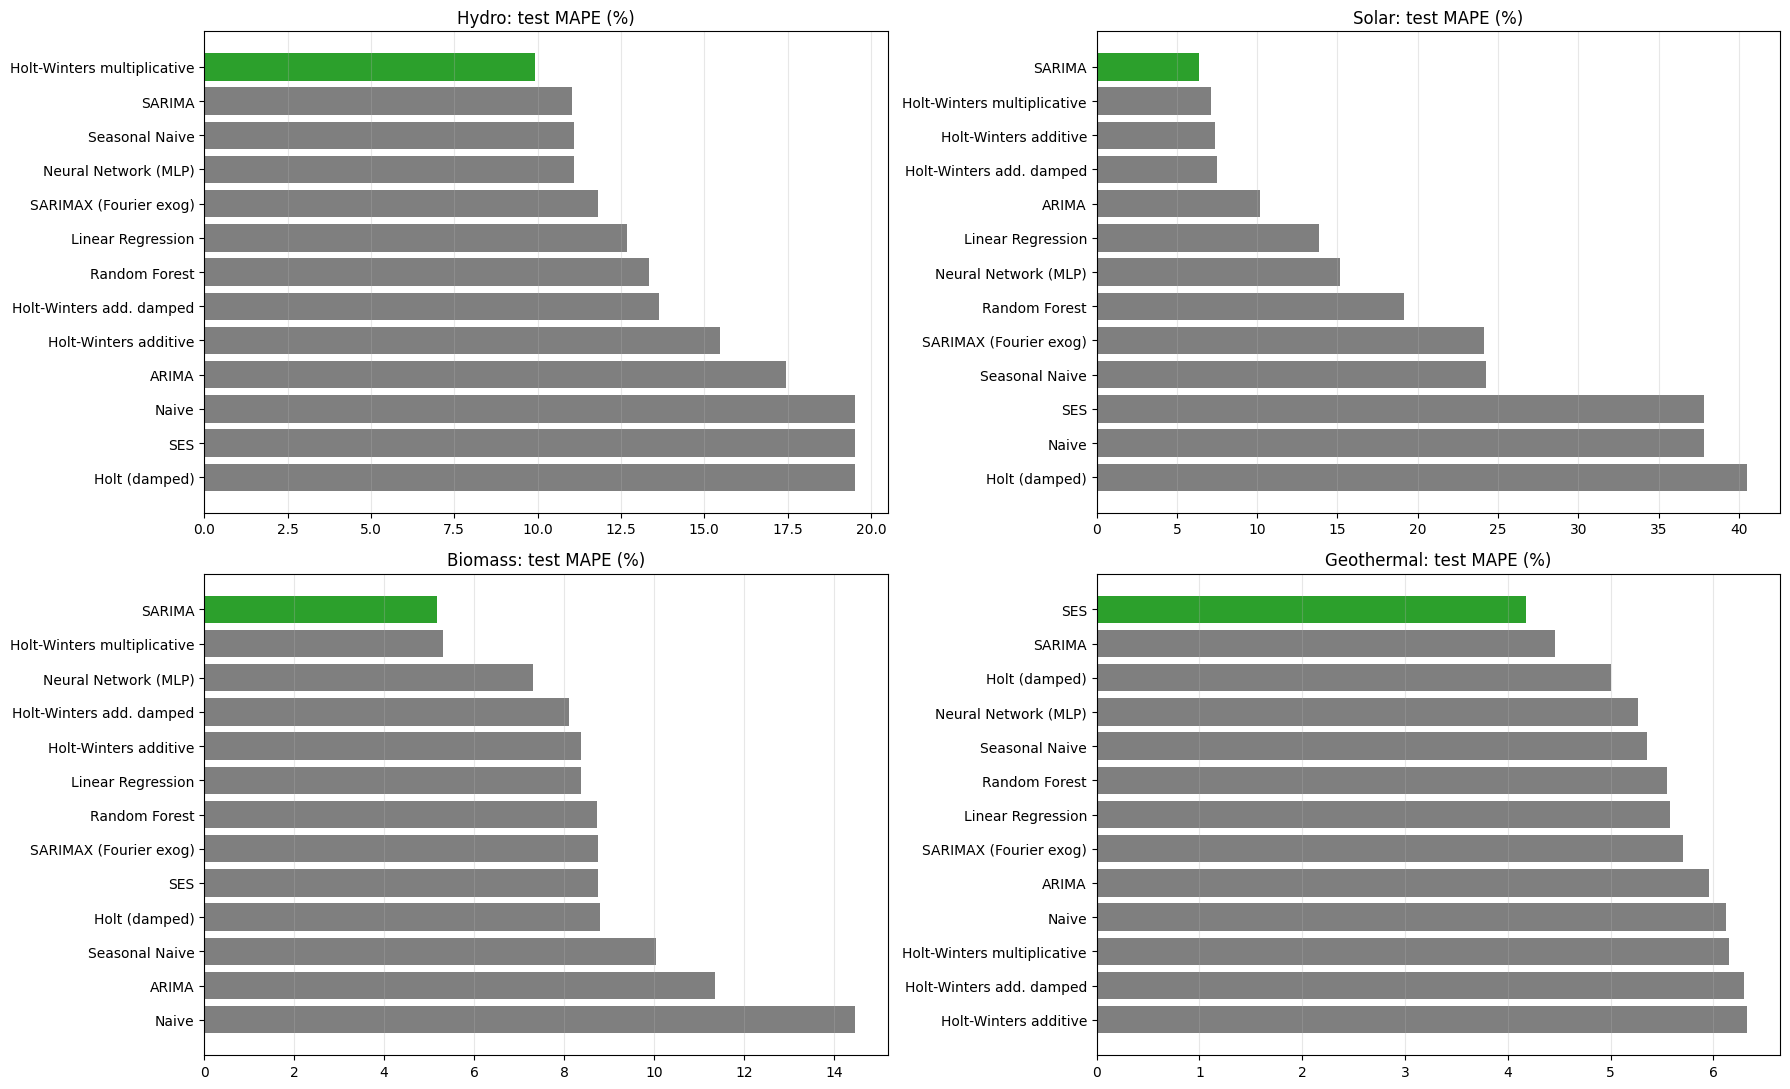

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, r in zip(axes.ravel(), RESOURCES):
    t = all_tables[r].sort_values("MAPE")
    ax.barh(t.index, t.MAPE, color=["tab:green" if i == 0 else "tab:gray" for i in range(len(t))])
    ax.invert_yaxis()
    ax.set_title(f"{r.capitalize()}: test MAPE (%)")
    ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

In [42]:
#@title Interpretation (generated from the results above)
NONSEAS = ["Naive", "SES", "Holt (damped)", "ARIMA"]
rows_md, notes = [], []
for r in RESOURCES:
    t = all_tables[r]; b = t.iloc[0]; sn = t.loc["Seasonal Naive"]
    rows_md.append(f"| {r.capitalize()} | {t.index[0]} | {b['MAPE']:.1f}% | {b['MASE']:.2f} | {sn['MAPE']:.1f}% | {(1 - b['MAE'] / sn['MAE']) * 100:+.0f}% |")
    ns = t.loc[[m for m in NONSEAS if m in t.index], "MAPE"].median()
    se = t.drop(index=[m for m in NONSEAS if m in t.index], errors="ignore")["MAPE"].median()
    notes.append((r, ns, se))
table = "\n".join(rows_md)
rank = sorted(RESOURCES, key=lambda r: all_tables[r].MAPE.iloc[0])
beat = [r for r in RESOURCES if all_tables[r].index[0] != "Seasonal Naive" and all_tables[r].MAPE.iloc[0] < all_tables[r].loc["Seasonal Naive", "MAPE"]]
def join_and(xs): return ", ".join(xs[:-1]) + " and " + xs[-1] if len(xs) > 1 else xs[0]
fam_win = pd.Series({r: all_tables[r].family.iloc[0] for r in RESOURCES})
n_hurt = sum(1 for _, ns, se in notes if se < ns)
seas_txt = "\n".join(f"  * {r.capitalize()}: median MAPE {ns:.1f}% for non-seasonal models (Naive, SES, Holt, ARIMA) versus {se:.1f}% for all the others." for r, ns, se in notes)
h2 = ("supported for " + join_and(beat) + (" but not for " + join_and([r for r in RESOURCES if r not in beat]) if len(beat) < 4 else " (all four)")) if beat else "not supported for any resource"
show(f"""**Model comparison across resources**

| Resource | Best model | MAPE | MASE | Seasonal naive MAPE | MAE improvement over seasonal naive |
|---|---|---|---|---|---|
{table}

* **Predictability (lowest to highest test MAPE):** {', '.join(f'{r} ({all_tables[r].MAPE.iloc[0]:.1f}%)' for r in rank)}.
* **No single model wins everywhere:** the best models are {', '.join(f'{all_tables[r].index[0]} for {r}' for r in RESOURCES)}. Winning families: {', '.join(f'{f} ({", ".join(fam_win[fam_win == f].index)})' for f in fam_win.unique())}.
* **Does ignoring seasonality hurt?** {n_hurt} of the 4 resources show a lower median MAPE for the models that include a seasonal component than for the non-seasonal ones:
{seas_txt}
* **H2 (the best model has a lower test MAPE than seasonal naive):** {h2}.
* Differences of a few percentage points between neighbouring models are within what 24 test months can resolve, so the choice between near-equal models should not be over-interpreted.""")

**Model comparison across resources**

| Resource | Best model | MAPE | MASE | Seasonal naive MAPE | MAE improvement over seasonal naive |
|---|---|---|---|---|---|
| Hydro | Holt-Winters multiplicative | 9.9% | 0.71 | 11.1% | +12% |
| Solar | SARIMA | 6.4% | 1.87 | 24.3% | +72% |
| Biomass | SARIMA | 5.2% | 0.73 | 10.0% | +49% |
| Geothermal | SES | 4.2% | 1.10 | 5.4% | +22% |

* **Predictability (lowest to highest test MAPE):** geothermal (4.2%), biomass (5.2%), solar (6.4%), hydro (9.9%).
* **No single model wins everywhere:** the best models are Holt-Winters multiplicative for hydro, SARIMA for solar, SARIMA for biomass, SES for geothermal. Winning families: Holt-Winters (hydro), SARIMA (solar, biomass), Exponential smoothing (geothermal).
* **Does ignoring seasonality hurt?** 3 of the 4 resources show a lower median MAPE for the models that include a seasonal component than for the non-seasonal ones:
  * Hydro: median MAPE 19.5% for non-seasonal models (Naive, SES, Holt, ARIMA) versus 11.8% for all the others.
  * Solar: median MAPE 37.9% for non-seasonal models (Naive, SES, Holt, ARIMA) versus 13.9% for all the others.
  * Biomass: median MAPE 10.1% for non-seasonal models (Naive, SES, Holt, ARIMA) versus 8.4% for all the others.
  * Geothermal: median MAPE 5.5% for non-seasonal models (Naive, SES, Holt, ARIMA) versus 5.6% for all the others.
* **H2 (the best model has a lower test MAPE than seasonal naive):** supported for hydro, solar, biomass and geothermal (all four).
* Differences of a few percentage points between neighbouring models are within what 24 test months can resolve, so the choice between near-equal models should not be over-interpreted.

## 10. Forecast of the next 12 months (Aug 2026 – Jul 2027)
The best model of each resource is re-fitted on **all** data up to Jul 2026 and forecasts the next 12 months. The band is an approximate 90% range taken from that model's test-period percentage errors.

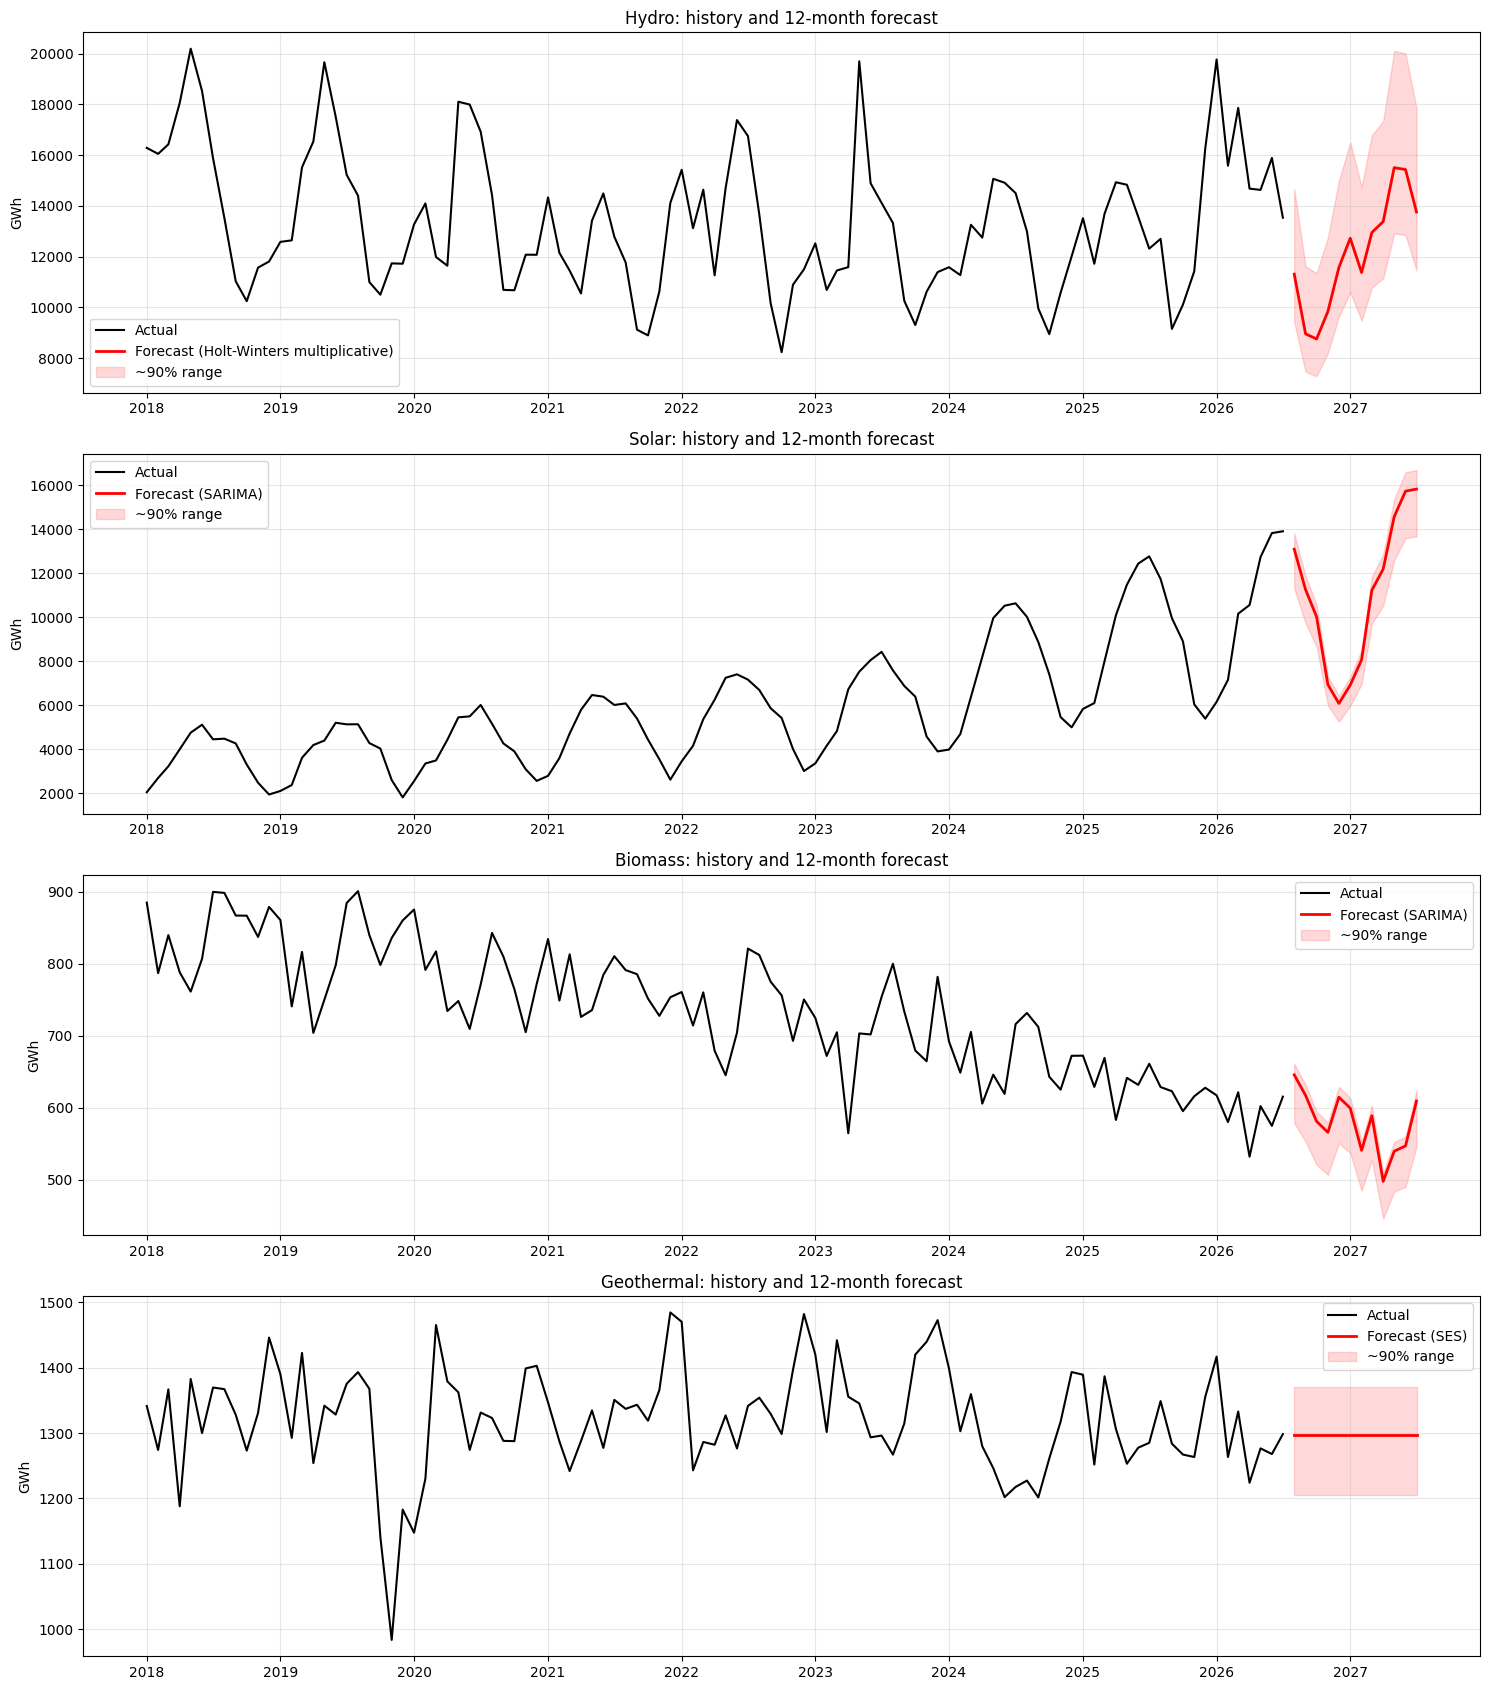

,best model,last 12 months (GWh),next 12 months forecast (GWh),change %,peak month,lowest month,"share of the four resources, next 12 m (%)"
hydro,Holt-Winters multiplicative,171592.166,145548.212,-15.178,May 2027,Oct 2026,48.506
solar,SARIMA,116602.120,131996.308,13.202,Jul 2027,Dec 2026,43.989
biomass,SARIMA,7233.331,6947.012,-3.958,Aug 2026,Apr 2027,2.315
geothermal,SES,15597.879,15572.391,-0.163,Aug 2026,Aug 2026,5.190


In [43]:
future = {}
for r in RESOURCES:
    best = all_tables[r].index[0]
    fc = MODELS[best][1](series[r], H_FUTURE, r)
    idx = pd.date_range(series[r].index[-1] + pd.offsets.MonthBegin(), periods=H_FUTURE, freq="MS")
    pct_err = (test[r] - all_forecasts[r][best]) / all_forecasts[r][best]
    lo, hi = np.quantile(pct_err, [0.05, 0.95])
    future[r] = pd.DataFrame({"forecast": fc, "lower_90": fc * (1 + lo), "upper_90": fc * (1 + hi)}, index=idx)

fig, axes = plt.subplots(4, 1, figsize=(15, 17))
for ax, r in zip(axes, RESOURCES):
    ax.plot(series[r].loc["2018-01-01":], color="black", label="Actual")
    ax.plot(future[r].forecast, color="red", linewidth=2, label=f"Forecast ({all_tables[r].index[0]})")
    ax.fill_between(future[r].index, future[r].lower_90, future[r].upper_90, color="red", alpha=0.15, label="~90% range")
    ax.set_title(f"{r.capitalize()}: history and 12-month forecast")
    ax.set_ylabel("GWh")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

outlook = pd.DataFrame({
    r: {"best model": all_tables[r].index[0],
        "last 12 months (GWh)": series[r].iloc[-12:].sum(),
        "next 12 months forecast (GWh)": future[r].forecast.sum(),
        "change %": (future[r].forecast.sum() / series[r].iloc[-12:].sum() - 1) * 100,
        "peak month": future[r].forecast.idxmax().strftime("%b %Y"),
        "lowest month": future[r].forecast.idxmin().strftime("%b %Y")}
    for r in RESOURCES}).T
outlook["share of the four resources, next 12 m (%)"] = (
    outlook["next 12 months forecast (GWh)"].astype(float) / outlook["next 12 months forecast (GWh)"].astype(float).sum() * 100)
outlook

In [44]:
print("Monthly forecasts (GWh):")
pd.DataFrame({r: future[r].forecast for r in RESOURCES}).round(1)

Monthly forecasts (GWh):


,hydro,solar,biomass,geothermal
2026-08-01,11308.800,13101.700,645.600,1297.700
2026-09-01,8955.200,11258.900,617.100,1297.700
2026-10-01,8751.100,10033.000,581.100,1297.700
2026-11-01,9839.000,6943.100,565.700,1297.700
2026-12-01,11570.600,6088.600,614.600,1297.700
2027-01-01,12724.900,6924.200,599.400,1297.700
2027-02-01,11373.100,8072.600,540.800,1297.700
2027-03-01,12948.100,11233.600,588.900,1297.700
2027-04-01,13380.700,12196.900,497.800,1297.700
2027-05-01,15507.300,14574.100,539.600,1297.700


In [45]:
#@title Interpretation (generated from the results above)
def join_and_f(xs): return ", ".join(xs[:-1]) + " and " + xs[-1] if len(xs) > 1 else xs[0]
rows_md = []
for r in RESOURCES:
    o = outlook.loc[r]
    f = future[r]
    width = ((f.upper_90 - f.lower_90) / f.forecast).mean() / 2 * 100
    rows_md.append(f"| {r.capitalize()} | {o['best model']} | {float(o['last 12 months (GWh)']):,.0f} | {float(o['next 12 months forecast (GWh)']):,.0f} | {float(o['change %']):+.1f}% "
                   f"| {o['peak month']} | {o['lowest month']} | ±{width:.0f}% |")
table = "\n".join(rows_md)
ch = outlook["change %"].astype(float)
flat = [r for r in RESOURCES if (future[r].forecast.max() - future[r].forecast.min()) / future[r].forecast.mean() < 0.01]
flat_note = (f"* The chosen model for {join_and_f(flat)} produces an almost flat forecast (no seasonal shape), so its 'peak' and 'lowest' months are not meaningful.\n" if flat else "")
sh = outlook["share of the four resources, next 12 m (%)"].astype(float)
show(f"""**Forecast for Aug 2026 – Jul 2027**

| Resource | Model | Last 12 months (GWh) | Next 12 months (GWh) | Change | Peak month | Lowest month | Typical ~90% band (monthly) |
|---|---|---|---|---|---|---|---|
{table}

{flat_note}* The largest expected change is for **{ch.abs().idxmax()}** ({ch[ch.abs().idxmax()]:+.1f}%), and the smallest for **{ch.abs().idxmin()}** ({ch[ch.abs().idxmin()]:+.1f}%).
* In the coming 12 months the four resources together are forecast to be split as: {', '.join(f'{r} {sh[r]:.0f}%' for r in RESOURCES)}.
* The bands come from the model's own errors on 24 test months, so they are approximate. They are widest for the resources that are hardest to predict, and they do not include the risk of a structural change (new capacity, plant closures, a very wet or dry year).
* Forecasts of one calendar year ahead are conditional on the patterns of the past continuing.""")

**Forecast for Aug 2026 – Jul 2027**

| Resource | Model | Last 12 months (GWh) | Next 12 months (GWh) | Change | Peak month | Lowest month | Typical ~90% band (monthly) |
|---|---|---|---|---|---|---|---|
| Hydro | Holt-Winters multiplicative | 171,592 | 145,548 | -15.2% | May 2027 | Oct 2026 | ±23% |
| Solar | SARIMA | 116,602 | 131,996 | +13.2% | Jul 2027 | Dec 2026 | ±10% |
| Biomass | SARIMA | 7,233 | 6,947 | -4.0% | Aug 2026 | Apr 2027 | ±6% |
| Geothermal | SES | 15,598 | 15,572 | -0.2% | Aug 2026 | Aug 2026 | ±6% |

* The chosen model for geothermal produces an almost flat forecast (no seasonal shape), so its 'peak' and 'lowest' months are not meaningful.
* The largest expected change is for **hydro** (-15.2%), and the smallest for **geothermal** (-0.2%).
* In the coming 12 months the four resources together are forecast to be split as: hydro 49%, solar 44%, biomass 2%, geothermal 5%.
* The bands come from the model's own errors on 24 test months, so they are approximate. They are widest for the resources that are hardest to predict, and they do not include the risk of a structural change (new capacity, plant closures, a very wet or dry year).
* Forecasts of one calendar year ahead are conditional on the patterns of the past continuing.

## 11. Residual analysis summary

In [46]:
pd.DataFrame(residual_rows).set_index(["resource", "model"])

n   mean  mean t-test p      std  \
resource   model                                                             
hydro      Holt-Winters multiplicative   60 15.582          0.948 1833.166   
           SARIMA (in-sample)           270 13.973          0.880 1523.909   
solar      SARIMA                        60 18.949          0.724  414.457   
           SARIMA (in-sample)           270 -0.004          0.761    0.242   
biomass    SARIMA                        60 -5.479          0.225   34.600   
           SARIMA (in-sample)           270 -3.283          0.154   37.755   
geothermal SES                           60 -2.396          0.842   92.527   
           SARIMA (in-sample)           270  0.826          0.775   47.379   

                                        Ljung-Box p (lag 6)  \
resource   model                                              
hydro      Holt-Winters multiplicative                0.018   
           SARIMA (in-sample)                         0.767   
solar      SARIMA                                     0.968   
           SARIMA (in-sample)                         0.814   
biomass    SARIMA                                     0.375   
           SARIMA (in-sample)                         0.699   
geothermal SES                                        0.000   
           SARIMA (in-sample)                         0.127   

                                        Ljung-Box p (lag 12)  Shapiro-Wilk p  
resource   model                                                              
hydro      Holt-Winters multiplicative                 0.021           0.003  
           SARIMA (in-sample)                          0.541           0.000  
solar      SARIMA                                      0.182           0.334  
           SARIMA (in-sample)                          0.507           0.000  
biomass    SARIMA                                      0.473           0.494  
           SARIMA (in-sample)                          0.743           0.000  
geothermal SES                                         0.001           0.081  
           SARIMA (in-sample)                          0.536           0.000

In [47]:
#@title Interpretation (generated from the results above)
R = pd.DataFrame(residual_rows)
R["is_sarima"] = R["model"].str.contains("SARIMA \\(in-sample\\)")
def flags(row):
    f = []
    if row["mean t-test p"] < 0.05: f.append("bias")
    if min(row["Ljung-Box p (lag 6)"], row["Ljung-Box p (lag 12)"]) < 0.05: f.append("autocorrelation")
    if row["Shapiro-Wilk p"] < 0.05: f.append("non-normality")
    return ", ".join(f) if f else "none"
R["issues"] = R.apply(flags, axis=1)
lines = "\n".join(f"| {row['resource'].capitalize()} | {row['model']} | {row['n']} | {row['issues']} |" for _, row in R.iterrows())
white = R[(R["issues"].str.contains("autocorrelation") == False)]
n_bias = int(R["issues"].str.contains("bias").sum()); n_nn = int(R["issues"].str.contains("non-normality").sum())
show(f"""**Residual analysis summary**

| Resource | Residuals of | n | Issues found (5% level) |
|---|---|---|---|
{lines}

* {len(white)} of the {len(R)} residual sets {'has' if len(white) == 1 else 'have'} **no significant autocorrelation**{'; the others still contain some structure that a better-specified model could exploit' if len(white) < len(R) else ''}.
* {n_bias} of the {len(R)} residual sets show a significant mean error (bias): a model that is systematically too high or too low over the window checked.
* {n_nn} of the {len(R)} show non-normal residuals. This is common for energy data with outages and unusual wet or dry years, and it affects interval widths more than point forecasts.""")

**Residual analysis summary**

| Resource | Residuals of | n | Issues found (5% level) |
|---|---|---|---|
| Hydro | Holt-Winters multiplicative | 60 | autocorrelation, non-normality |
| Hydro | SARIMA (in-sample) | 270 | non-normality |
| Solar | SARIMA | 60 | none |
| Solar | SARIMA (in-sample) | 270 | non-normality |
| Biomass | SARIMA | 60 | none |
| Biomass | SARIMA (in-sample) | 270 | non-normality |
| Geothermal | SES | 60 | autocorrelation |
| Geothermal | SARIMA (in-sample) | 270 | non-normality |

* 6 of the 8 residual sets have **no significant autocorrelation**; the others still contain some structure that a better-specified model could exploit.
* 0 of the 8 residual sets show a significant mean error (bias): a model that is systematically too high or too low over the window checked.
* 5 of the 8 show non-normal residuals. This is common for energy data with outages and unusual wet or dry years, and it affects interval widths more than point forecasts.

## 12. Research Conclusion

In [48]:
#@title Interpretation (generated from the results above)
def peak_trough(r):
    s = series[r]; ratio = (s / s.rolling(12, center=True).mean()).dropna(); p = ratio.groupby(ratio.index.month).mean()
    return int(p.idxmax()), (p.max() - 1) * 100, int(p.idxmin()), (p.min() - 1) * 100
last12, prev12 = {r: series[r].iloc[-12:].sum() for r in RESOURCES}, {r: series[r].iloc[-24:-12].sum() for r in RESOURCES}
lines = []
for r in RESOURCES:
    pk, pa, tr, ta = peak_trough(r)
    t = all_tables[r]
    lines.append(f"* **{r.capitalize()}:** last 12 months {last12[r]:,.0f} GWh ({(last12[r] / prev12[r] - 1) * 100:+.1f}% on the year before). Seasonal peak in {MONTH_NAME[pk]} ({pa:+.0f}%) and low in {MONTH_NAME[tr]} ({ta:+.0f}%). "
                 f"Best model: **{t.index[0]}** (test MAPE {t.MAPE.iloc[0]:.1f}%, MASE {t.MASE.iloc[0]:.2f}); next 12 months forecast {float(outlook.loc[r, 'change %']):+.1f}% versus the last 12.")
nl = "\n".join(lines)
rank = sorted(RESOURCES, key=lambda r: all_tables[r].MAPE.iloc[0])
show(f"""**Answer to the research question**

Hydro, solar, biomass and geothermal behave very differently in the Western U.S. region, and each is best forecast with its own model:

{nl}

**What the analysis shows**

* **Trend:** each resource follows its own long-term path (Review 1): solar grows strongly, hydro varies with wet and dry years, biomass has risen and then declined, and geothermal changes slowly.
* **Seasonality:** all four have a yearly cycle, but with different strength and timing, so a seasonal component is needed in the models.
* **Temporal dependence:** the differencing needed to make each series stationary and the ACF/PACF structure differ by resource, which is why one common model is not appropriate.
* **Forecast accuracy** (test MAPE, best first): {', '.join(f'{r} {all_tables[r].MAPE.iloc[0]:.1f}%' for r in rank)}. {rank[0].capitalize()} is the most predictable and {rank[-1]} the least.

**Limitations**

* The evaluation uses a single chronological split with 24 test months, so close rankings are not conclusive.
* The series are regional totals of 13 states; no weather, rainfall, snowpack, capacity or price data are used, which limits what the models can know, especially for hydro.
* The ~90% bands are approximate and based on a small number of test errors.
* The forecasts assume the established patterns continue for the next 12 months.""")

**Answer to the research question**

Hydro, solar, biomass and geothermal behave very differently in the Western U.S. region, and each is best forecast with its own model:

* **Hydro:** last 12 months 171,592 GWh (+15.1% on the year before). Seasonal peak in May (+29%) and low in Oct (-27%). Best model: **Holt-Winters multiplicative** (test MAPE 9.9%, MASE 0.71); next 12 months forecast -15.2% versus the last 12.
* **Solar:** last 12 months 116,602 GWh (+12.6% on the year before). Seasonal peak in Jun (+54%) and low in Dec (-58%). Best model: **SARIMA** (test MAPE 6.4%, MASE 1.87); next 12 months forecast +13.2% versus the last 12.
* **Biomass:** last 12 months 7,233 GWh (-8.1% on the year before). Seasonal peak in Aug (+8%) and low in Apr (-10%). Best model: **SARIMA** (test MAPE 5.2%, MASE 0.73); next 12 months forecast -4.0% versus the last 12.
* **Geothermal:** last 12 months 15,598 GWh (+0.3% on the year before). Seasonal peak in Dec (+5%) and low in Feb (-6%). Best model: **SES** (test MAPE 4.2%, MASE 1.10); next 12 months forecast -0.2% versus the last 12.

**What the analysis shows**

* **Trend:** each resource follows its own long-term path (Review 1): solar grows strongly, hydro varies with wet and dry years, biomass has risen and then declined, and geothermal changes slowly.
* **Seasonality:** all four have a yearly cycle, but with different strength and timing, so a seasonal component is needed in the models.
* **Temporal dependence:** the differencing needed to make each series stationary and the ACF/PACF structure differ by resource, which is why one common model is not appropriate.
* **Forecast accuracy** (test MAPE, best first): geothermal 4.2%, biomass 5.2%, solar 6.4%, hydro 9.9%. Geothermal is the most predictable and hydro the least.

**Limitations**

* The evaluation uses a single chronological split with 24 test months, so close rankings are not conclusive.
* The series are regional totals of 13 states; no weather, rainfall, snowpack, capacity or price data are used, which limits what the models can know, especially for hydro.
* The ~90% bands are approximate and based on a small number of test errors.
* The forecasts assume the established patterns continue for the next 12 months.